#  Road Damage Detection: Model Training

## 1. Setup
**Objective:** prepare the training environment: install dependencies, locate the cleaned dataset, and verify it before training.

**Input:** cleaned dataset (6 classes, group-split by source image to avoid leakage), built in the data-preparation notebook.

In [2]:
!pip install -q -U ultralytics

import ultralytics
print("ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics: 8.4.191


In [3]:
import os, shutil, time, yaml, torch
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle")
BASE = Path("/kaggle/working") if ON_KAGGLE else Path("/content")

INPUT_DIR = Path("/kaggle/input/datasets/osmanahmedosman/road-damage-detection-cleaned-dataset/road_damage_clean")
CLEAN_DIR = BASE / "road_damage_clean"
RUNS_DIR = str(BASE / "road_damage_runs")

print("Platform:", "Kaggle" if ON_KAGGLE else "Colab/other")
print("Input exists:", INPUT_DIR.exists())

Platform: Kaggle
Input exists: True


In [4]:
# Remove the incomplete working copy, if it exists
if CLEAN_DIR.exists():
    shutil.rmtree(CLEAN_DIR)

In [5]:
shutil.copytree(INPUT_DIR, CLEAN_DIR)

cfg = yaml.safe_load(open(CLEAN_DIR / "data.yaml"))
cfg["path"] = str(CLEAN_DIR)
with open(CLEAN_DIR / "data.yaml", "w") as f:
    yaml.dump(cfg, f, sort_keys=False)

print(cfg)

{'path': '/kaggle/working/road_damage_clean', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 6, 'names': ['alligator', 'block', 'crack', 'longitudinal', 'pothole', 'transverse']}


In [6]:
import pandas as pd

rows_check = []

for split in ["train", "valid", "test"]:
    n_images = len(list((CLEAN_DIR / split / "images").iterdir()))
    n_labels = len(list((CLEAN_DIR / split / "labels").iterdir()))

    rows_check.append({
        "split": split,
        "images": n_images,
        "labels": n_labels
    })

rows_check = pd.DataFrame(rows_check)
rows_check

,split,images,labels
0,train,4851,4851
1,valid,1238,1238
2,test,667,667


In [12]:
BASE_CFG = dict(
    data=str(CLEAN_DIR / "data.yaml"),
    imgsz=640,
    epochs=30,
    patience=10,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    seed=42,
    workers=4,
    device=0,
    project=RUNS_DIR,
    exist_ok=True,
)

MODELS = {
    "yolov8s": "yolov8s.pt",
    "yolo11s": "yolo11s.pt",
    "yolo26s": "yolo26s.pt",
}

In [8]:
print("CUDA available:", torch.cuda.is_available())
!nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv

CUDA available: True
name, memory.used [MiB], memory.total [MiB]
Tesla T4, 3 MiB, 15360 MiB
Tesla T4, 3 MiB, 15360 MiB


In [9]:
from ultralytics import YOLO

sample_img = str(next((CLEAN_DIR / "valid" / "images").iterdir()))
m = YOLO(MODELS["yolov8s"])

m.predict(sample_img, device=0, verbose=False)            # warm-up
result = m.predict(sample_img, device=0, verbose=False)
print(result[0].speed)

{'preprocess': 0.9211330000198359, 'inference': 16.321290999940175, 'postprocess': 0.5338049999181749}


## YOLOv8s

In [ ]:
MODEL_NAME = "yolov8s"      # change per commit: yolov8s | yolo11s | yolo26s

t0 = time.time()
model = YOLO(MODELS[MODEL_NAME])
model.train(**{**BASE_CFG, "name": MODEL_NAME})
print(f"{MODEL_NAME} finished in {(time.time() - t0) / 60:.1f} min")

,epoch,metrics/mAP50(B),metrics/mAP50-95(B)
24,25,0.47574,0.27480
25,26,0.48870,0.28385
26,27,0.49356,0.28654
27,28,0.49621,0.29055
28,29,0.50439,0.29575
29,30,0.50981,0.30027


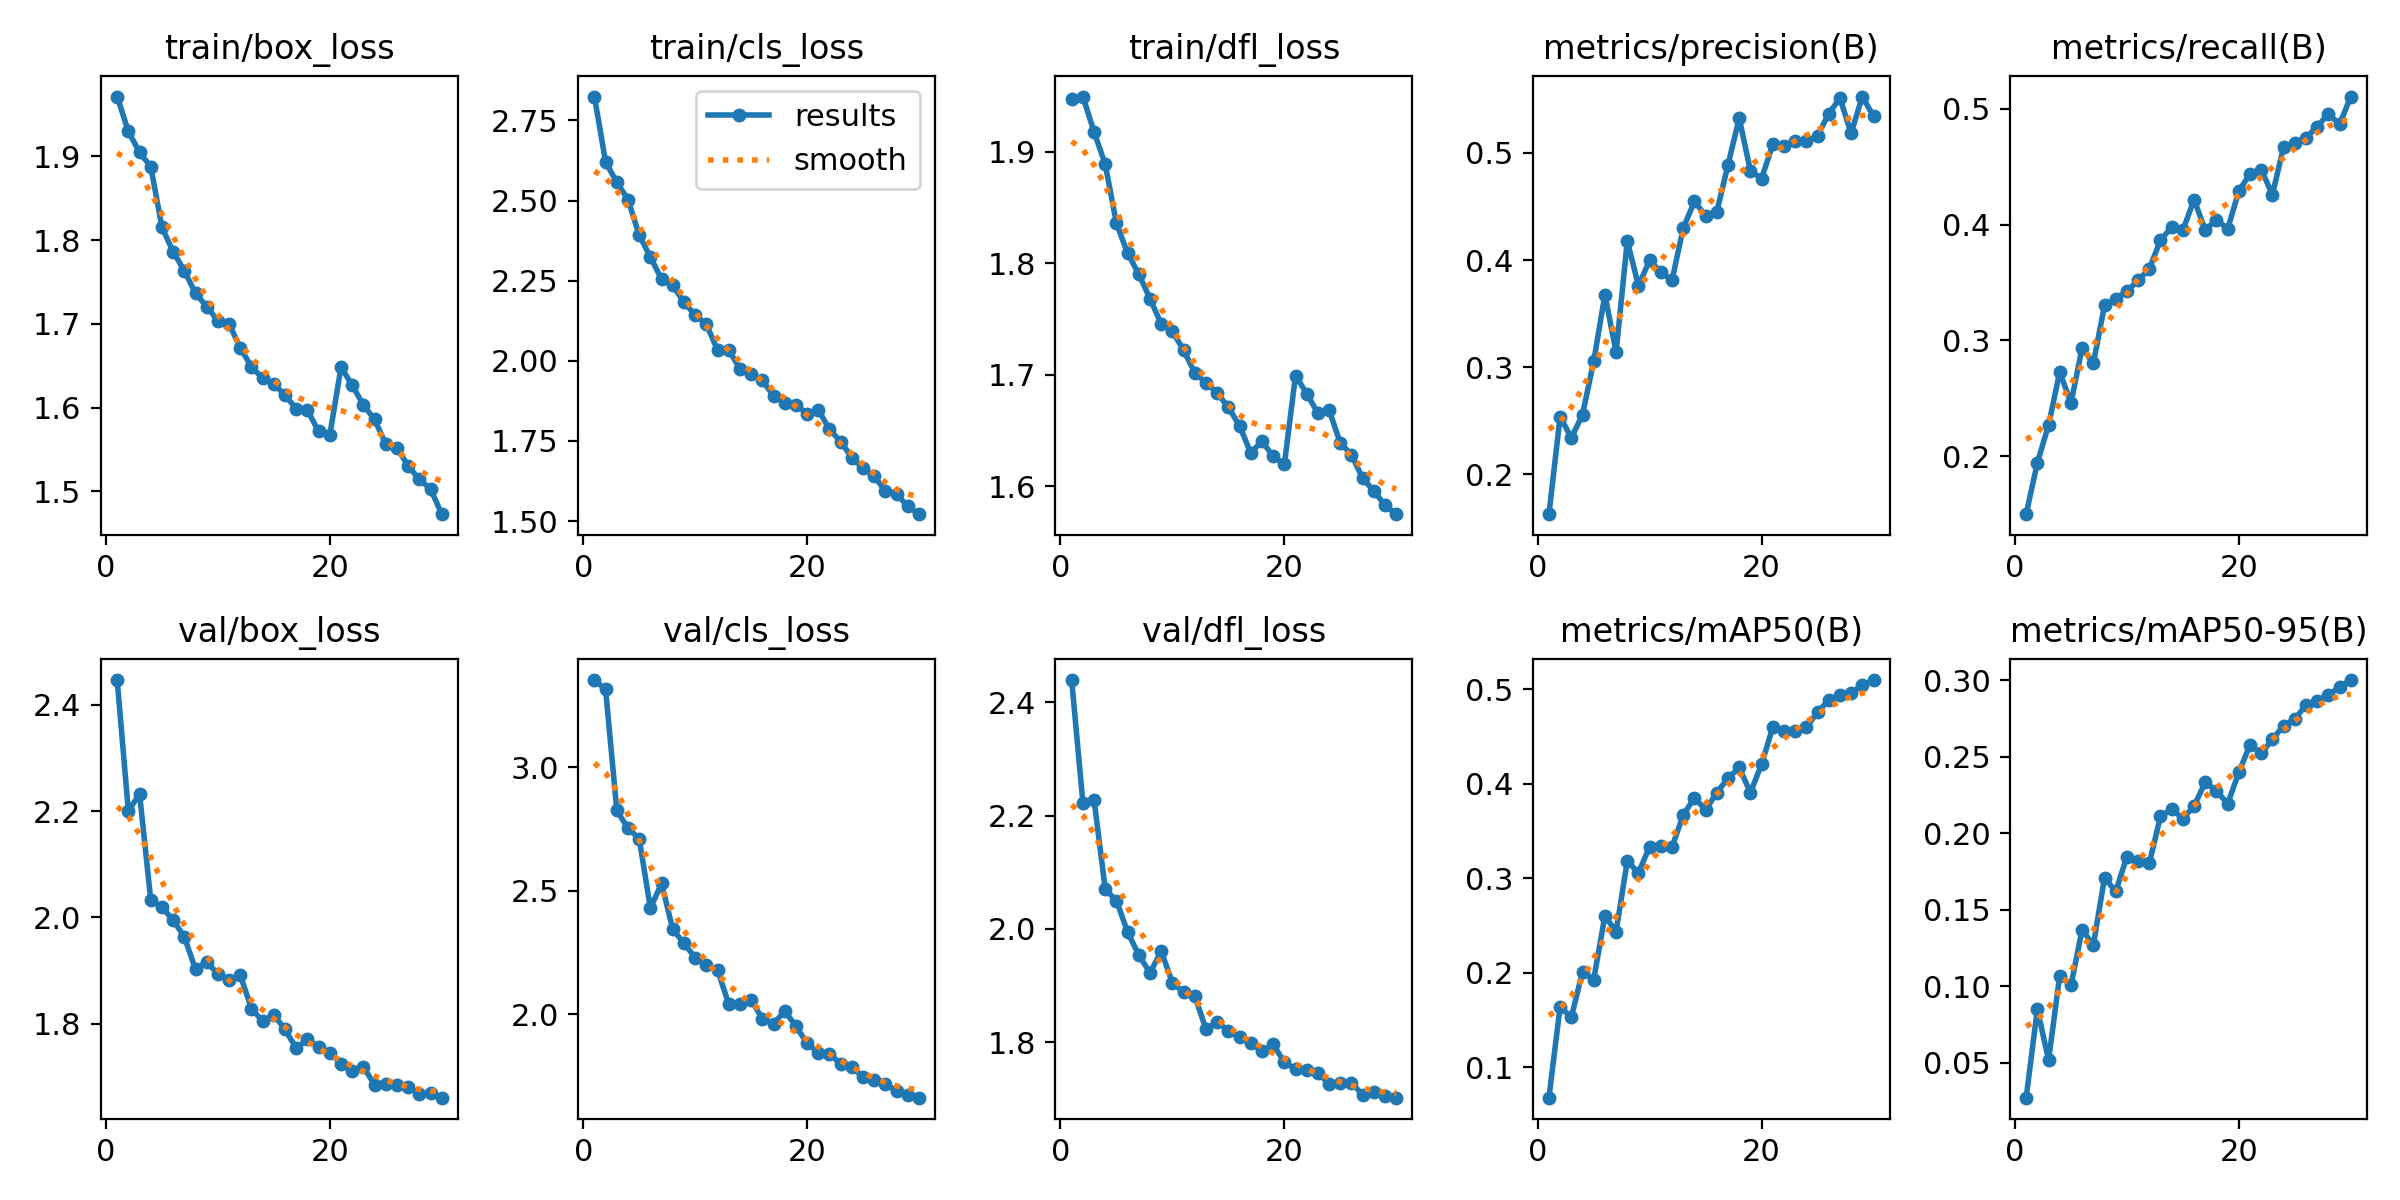

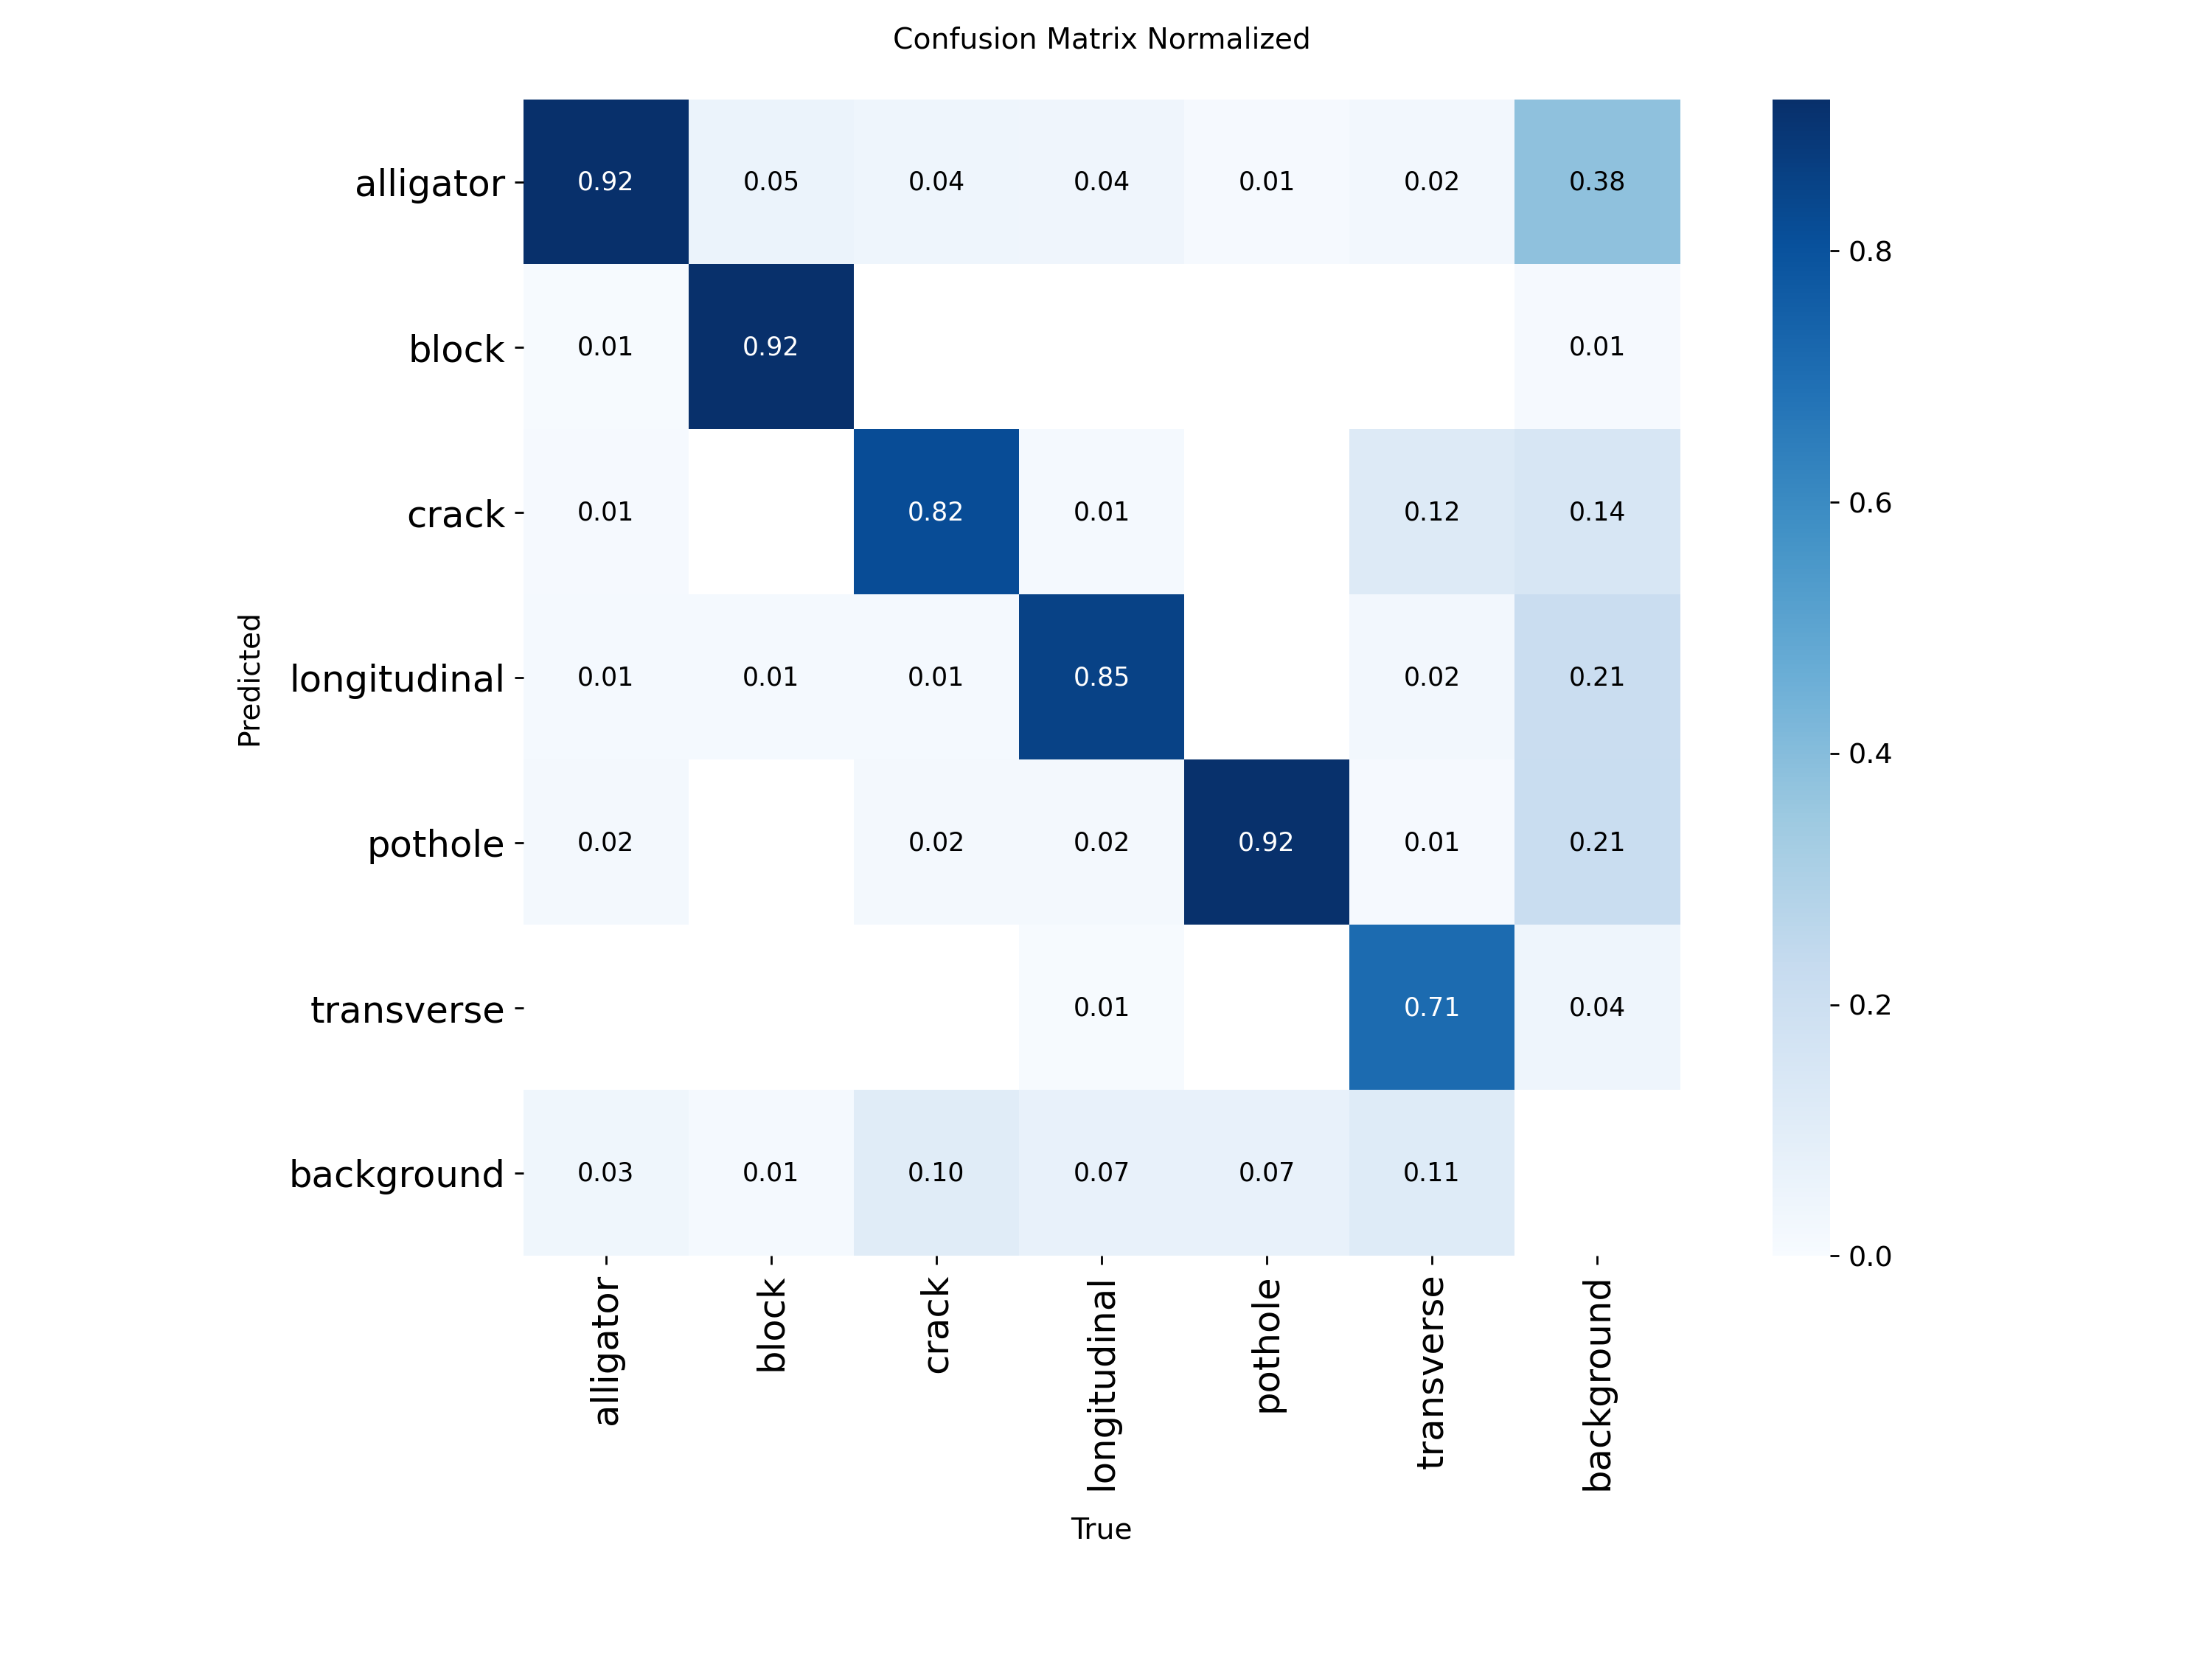

In [17]:
import pandas as pd
from IPython.display import Image, display

run_dir = Path(RUNS_DIR) / "yolov8s"
df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

display(df[["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(6))
display(Image(filename=str(run_dir / "results.png")))
display(Image(filename=str(run_dir / "confusion_matrix_normalized.png")))

In [14]:
shutil.make_archive("/kaggle/working/yolov8s_run", "zip", Path(RUNS_DIR) / "yolov8s")
print(os.listdir("/kaggle/working"))

['.virtual_documents', 'weights', 'yolov8s.pt', 'road_damage_clean', 'yolov8s_run.zip', 'road_damage_runs']


## YOLOv11s

In [19]:
assert torch.cuda.is_available(), "No GPU: enable an accelerator in Settings"
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


In [20]:
MODEL_NAME = "yolo11s"   

t0 = time.time()
model = YOLO(MODELS[MODEL_NAME])
model.train(**{**BASE_CFG, "name": MODEL_NAME})
print(f"{MODEL_NAME} finished in {(time.time() - t0) / 60:.1f} min")

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_clean/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s, nbs=64, nms=None, opset=None, optimi

,epoch,metrics/mAP50(B),metrics/mAP50-95(B)
24,25,0.49112,0.28642
25,26,0.48787,0.29299
26,27,0.49886,0.29547
27,28,0.50100,0.29959
28,29,0.50147,0.30411
29,30,0.51261,0.30617


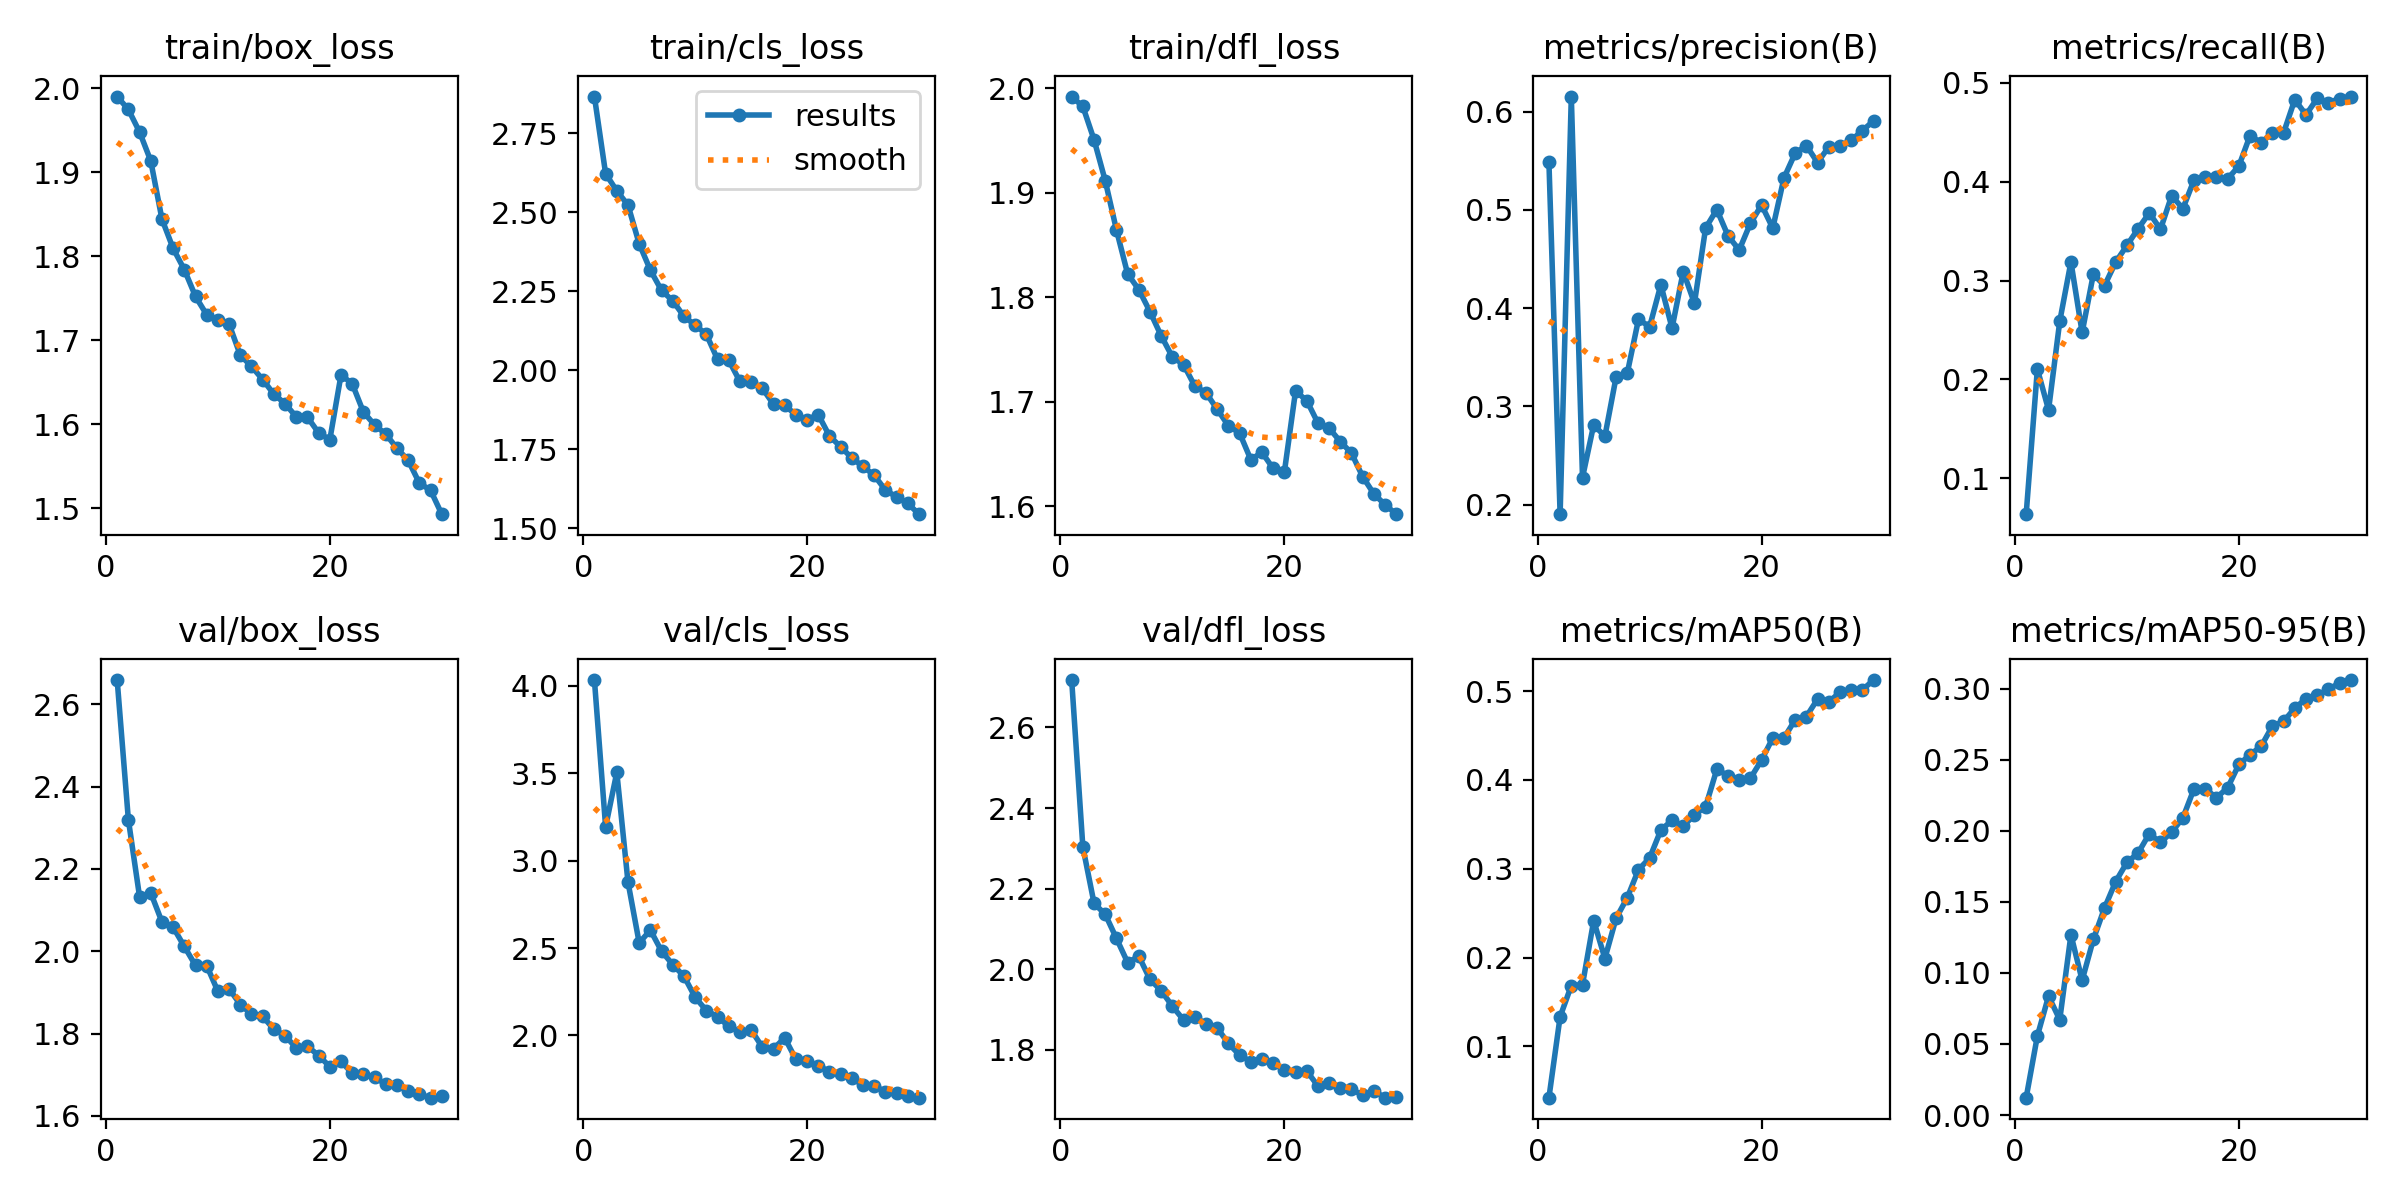

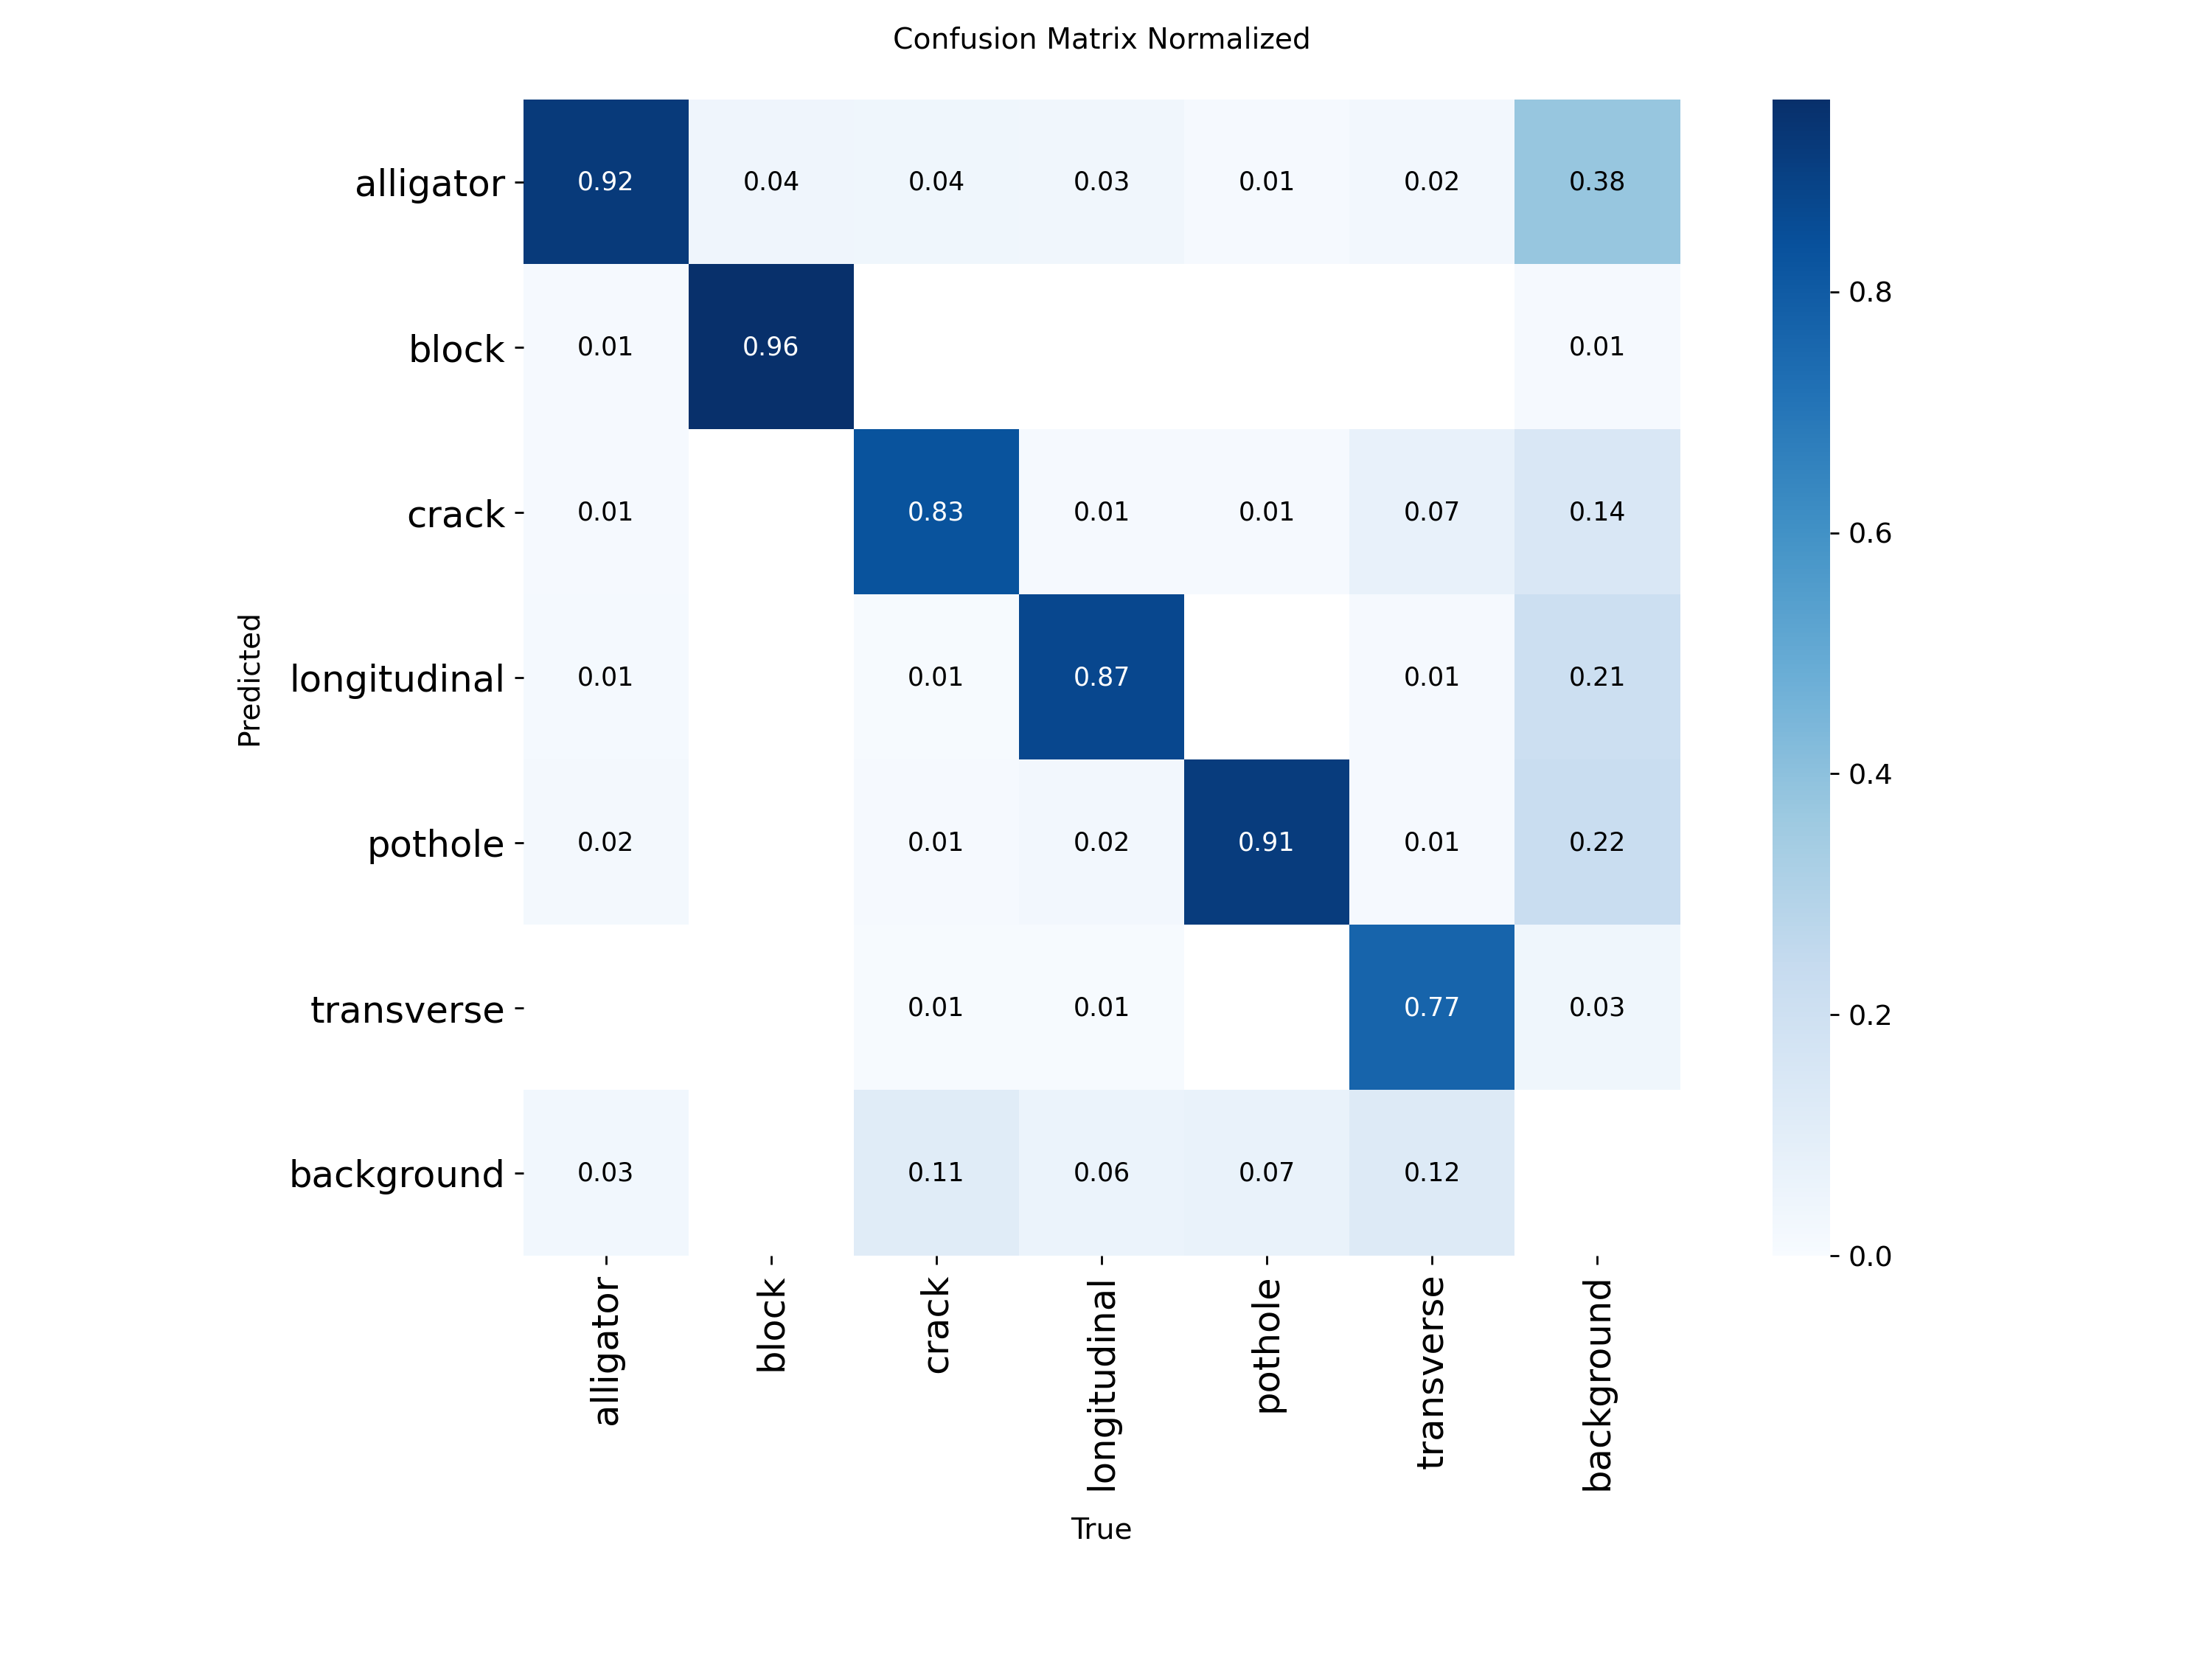

In [22]:
import pandas as pd
from IPython.display import Image, display

run_dir = Path(RUNS_DIR) / "yolo11s"
df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

display(df[["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(6))
display(Image(filename=str(run_dir / "results.png")))
display(Image(filename=str(run_dir / "confusion_matrix_normalized.png")))

In [24]:
shutil.make_archive("/kaggle/working/yolov11s_run", "zip", Path(RUNS_DIR) / "yolo11s")
print(os.listdir("/kaggle/working"))

['.virtual_documents', 'weights', 'yolov8s.pt', 'yolo11s.pt', 'yolov11s_run.zip', 'road_damage_clean', 'yolov8s_run.zip', 'road_damage_runs']


## YOLOv26s

In [25]:
assert torch.cuda.is_available(), "No GPU: enable an accelerator in Settings"
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


In [26]:
MODEL_NAME = "yolo26s"   

t0 = time.time()
model = YOLO(MODELS[MODEL_NAME])
model.train(**{**BASE_CFG, "name": MODEL_NAME})
print(f"{MODEL_NAME} finished in {(time.time() - t0) / 60:.1f} min")

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_clean/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s, nbs=64, nms=None, opset=None, optimi

,epoch,metrics/mAP50(B),metrics/mAP50-95(B)
24,25,0.52758,0.31274
25,26,0.54054,0.31986
26,27,0.54054,0.32511
27,28,0.54689,0.32715
28,29,0.54637,0.32676
29,30,0.54803,0.32821


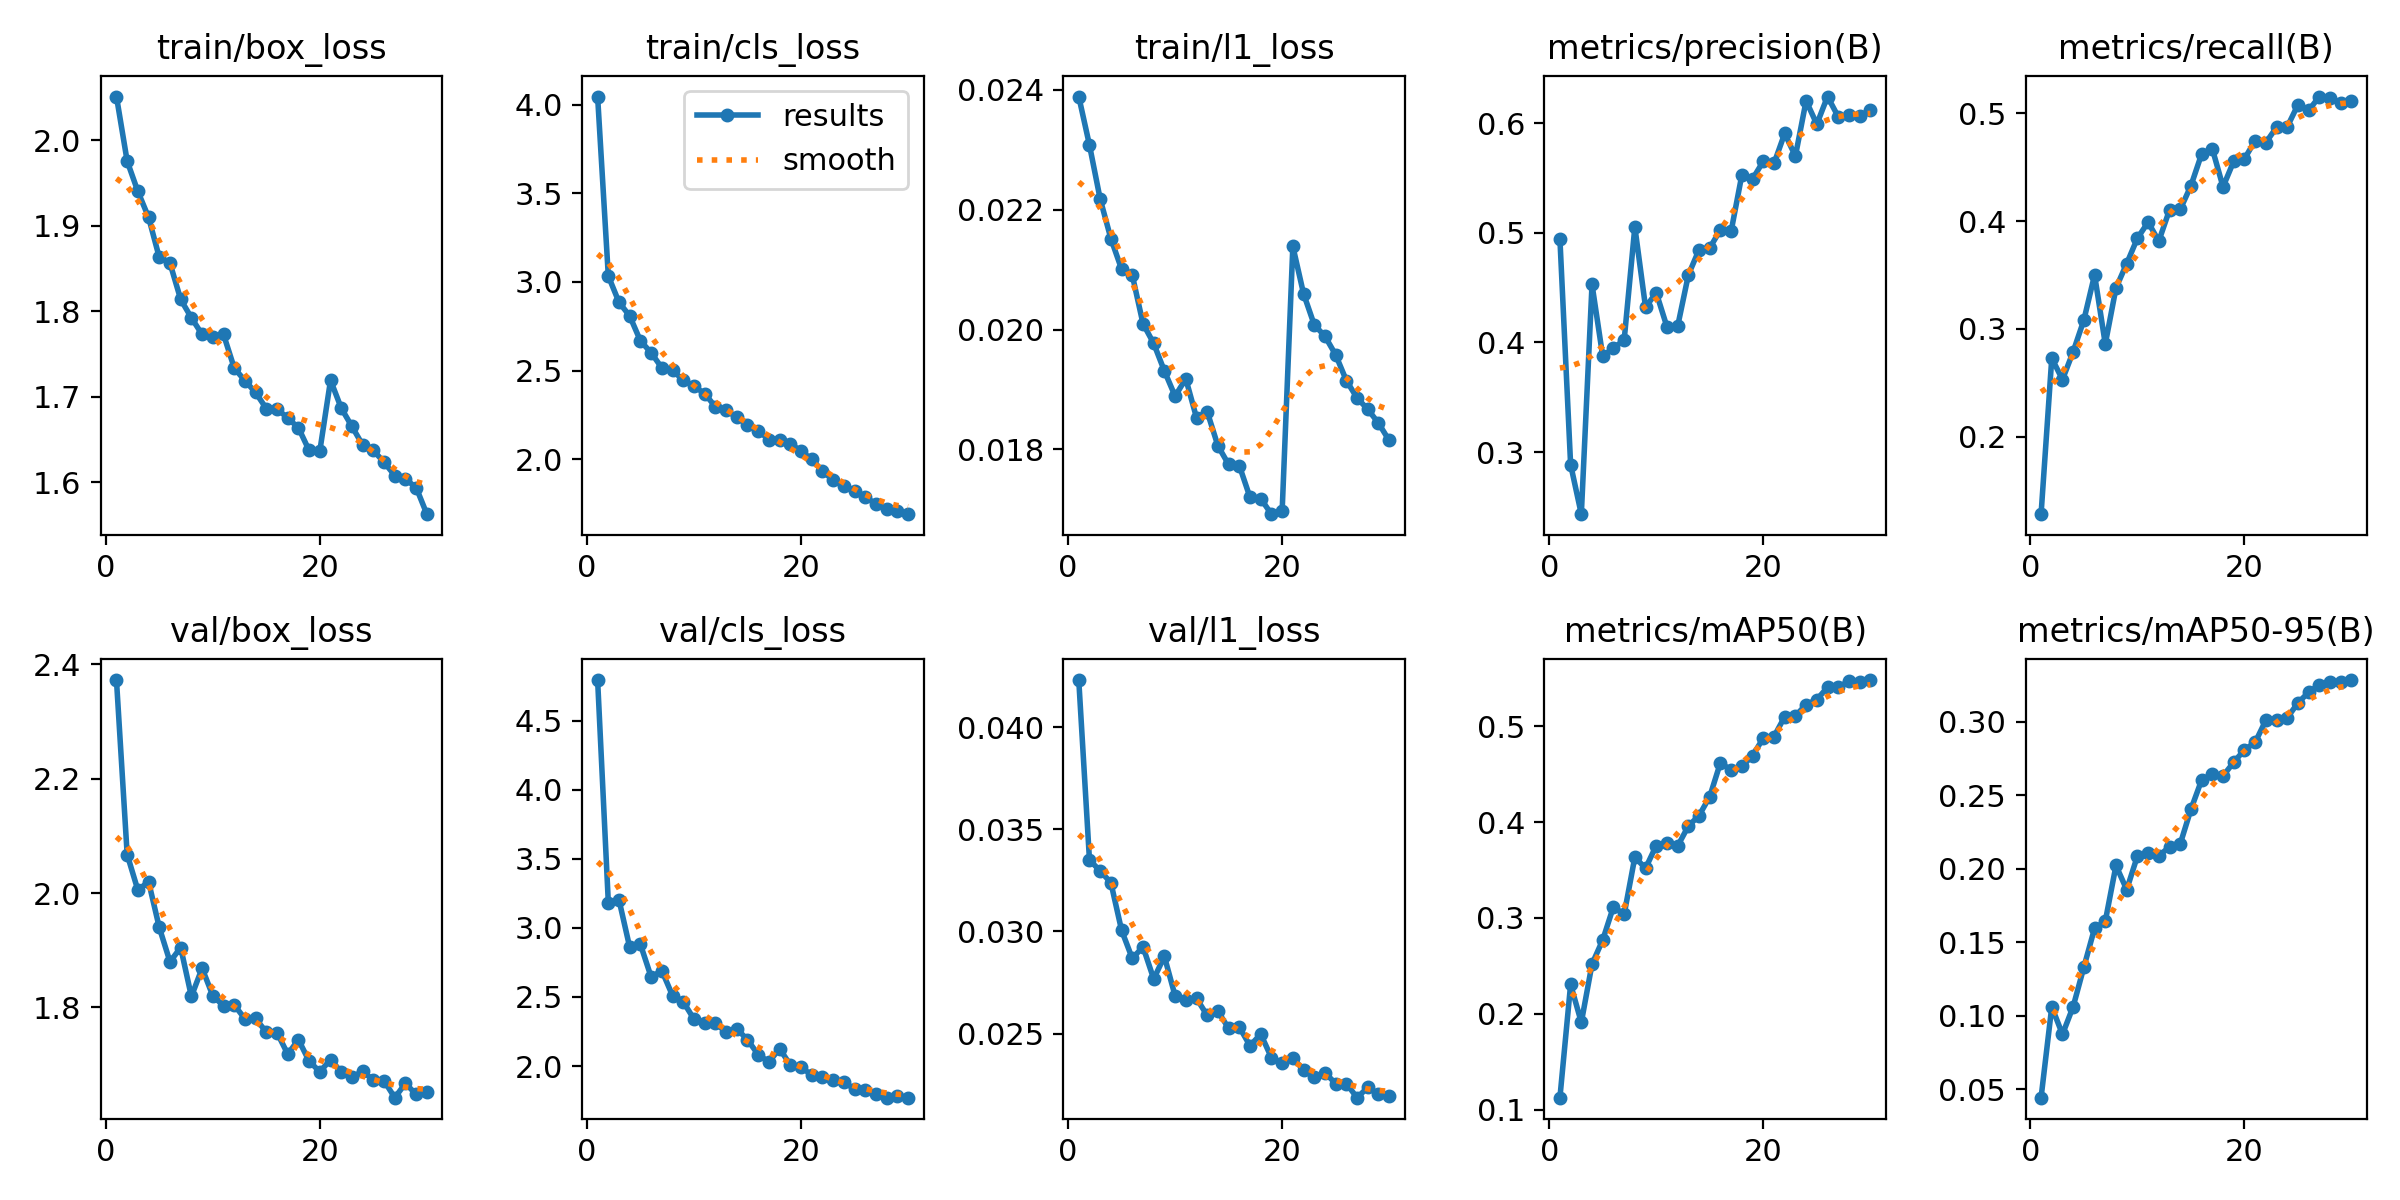

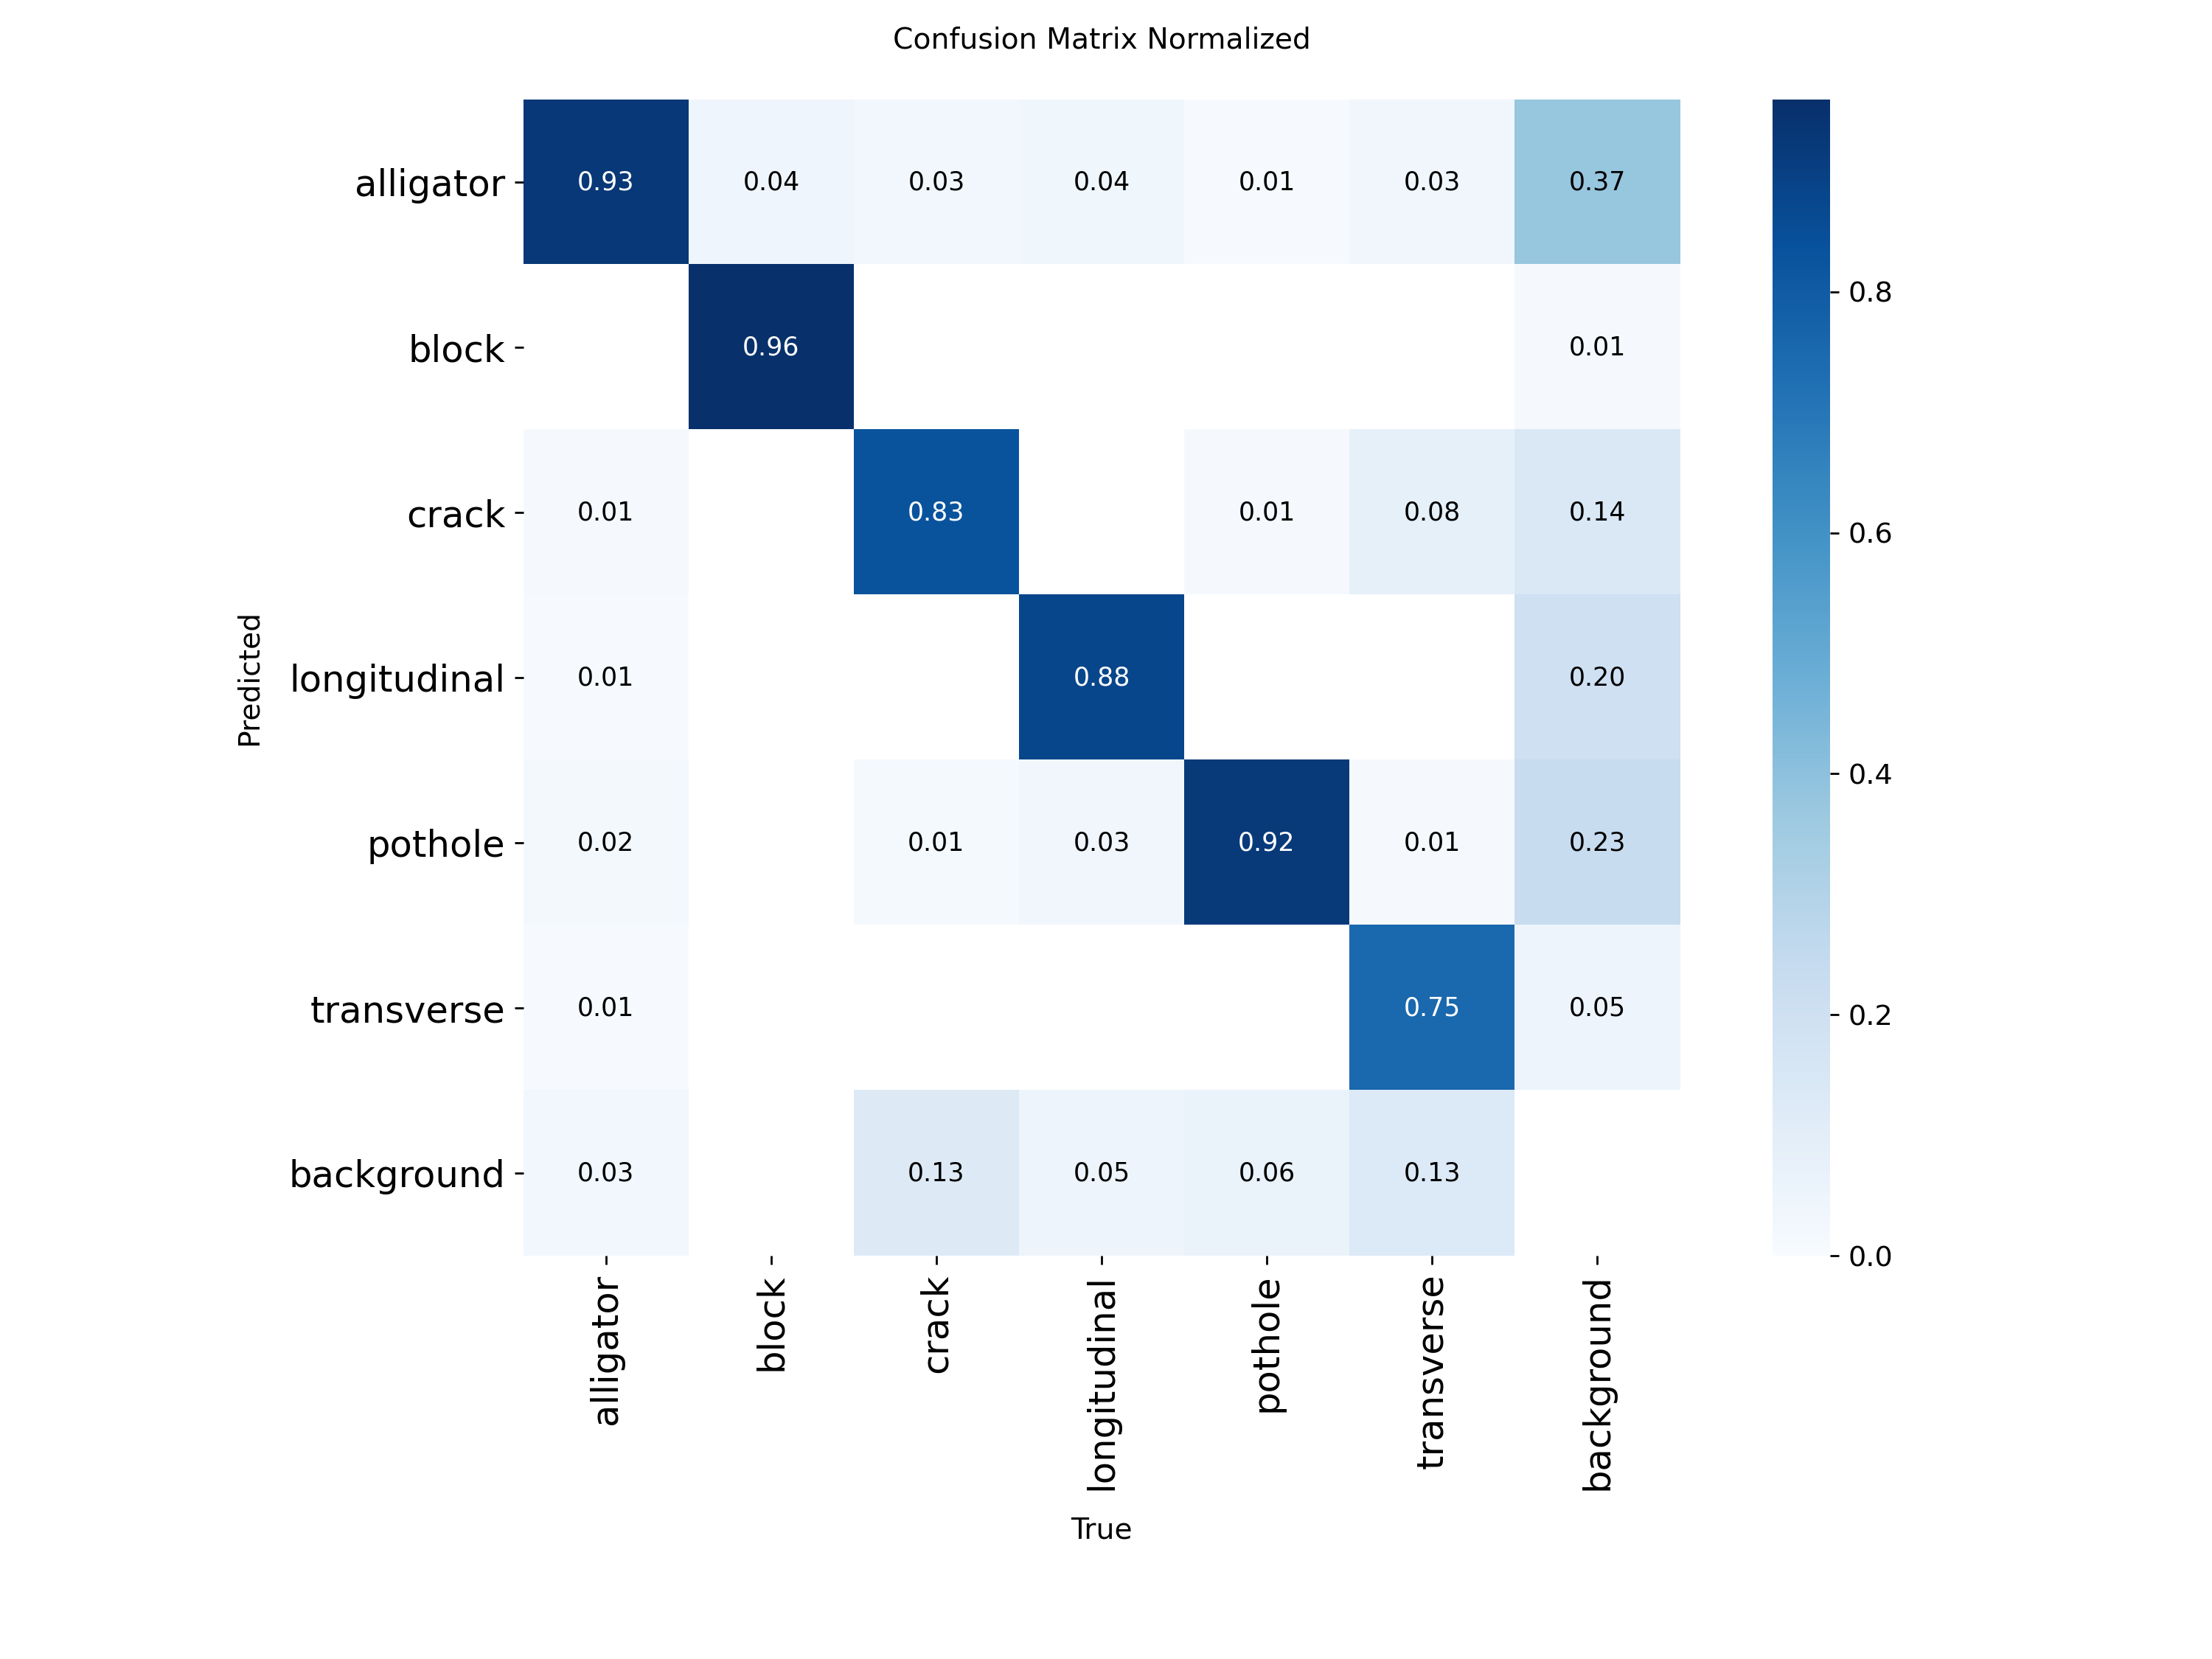

In [29]:
import pandas as pd
from IPython.display import Image, display

run_dir = Path(RUNS_DIR) / "yolo26s"
df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

display(df[["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(6))
display(Image(filename=str(run_dir / "results.png")))
display(Image(filename=str(run_dir / "confusion_matrix_normalized.png")))

In [28]:
shutil.make_archive("/kaggle/working/yolov26s_run", "zip", Path(RUNS_DIR) / "yolo26s")
print(os.listdir("/kaggle/working"))

['.virtual_documents', 'weights', 'yolo26s.pt', 'yolov8s.pt', 'yolo11s.pt', 'yolov11s_run.zip', 'road_damage_clean', 'yolov8s_run.zip', 'road_damage_runs', 'yolov26s_run.zip']


### Results & Interpretation: Baseline Comparison
| Model | mAP50 | mAP50-95 | P | R | Params | GFLOPs | Weights | Train time |
|---|---|---|---|---|---|---|---|---|
| YOLOv8s | 0.510 | 0.300 | 0.534 | 0.511 | 11.13M | 28.4 | 22.5 MB | 33.6 min |
| YOLO11s | 0.512 | 0.307 | 0.590 | 0.486 | 9.42M | 21.4 | 19.2 MB | 35.3 min |
| YOLO26s | **0.548** | **0.328** | 0.612 | 0.512 | 9.47M | 20.8 | 20.3 MB | 41.8 min |

- **YOLO26s leads** by about 3.8 mAP50 points over the other two; YOLOv8s and YOLO11s are within 1 point of each other and not distinguishable from a single run.
- **Gains concentrate on thin-crack classes** (`crack`, `longitudinal`, `transverse`), where box precision matters most.
- **`alligator` recall is ≈0.24 for all three architectures**, which suggests a data or class-definition issue rather than a capacity limit (to be checked in the confusion matrix).
- **v8s and 11s were still improving at epoch 30**; part of the late rise comes from LR decay and mosaic shutdown, so under-training is a hypothesis to test with longer schedules.

**Limits:** one run per model (no variance estimate); validation set only; identical settings (AdamW, lr 0.001) are fair but not necessarily optimal per model; inference speed from training logs is unreliable and is re-measured in Section 5.

# Hyperparameter Tuning
## yolo26s-tune-imgsz800

In [31]:
assert torch.cuda.is_available(), "No GPU: enable an accelerator in Settings"
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


In [32]:
MODEL_NAME = "yolo26s"
EXP_NAME = "yolo26s_imgsz800"

t0 = time.time()
model = YOLO(MODELS[MODEL_NAME])
model.train(**{**BASE_CFG, "imgsz": 800, "name": EXP_NAME})
print(f"{EXP_NAME} finished in {(time.time() - t0) / 60:.1f} min")

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_clean/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_imgsz800, nbs=64, nms=None, opset=Non

,epoch,metrics/mAP50(B),metrics/mAP50-95(B)
24,25,0.52782,0.30799
25,26,0.52614,0.31404
26,27,0.53539,0.31755
27,28,0.53699,0.31631
28,29,0.53689,0.31851
29,30,0.53993,0.31945


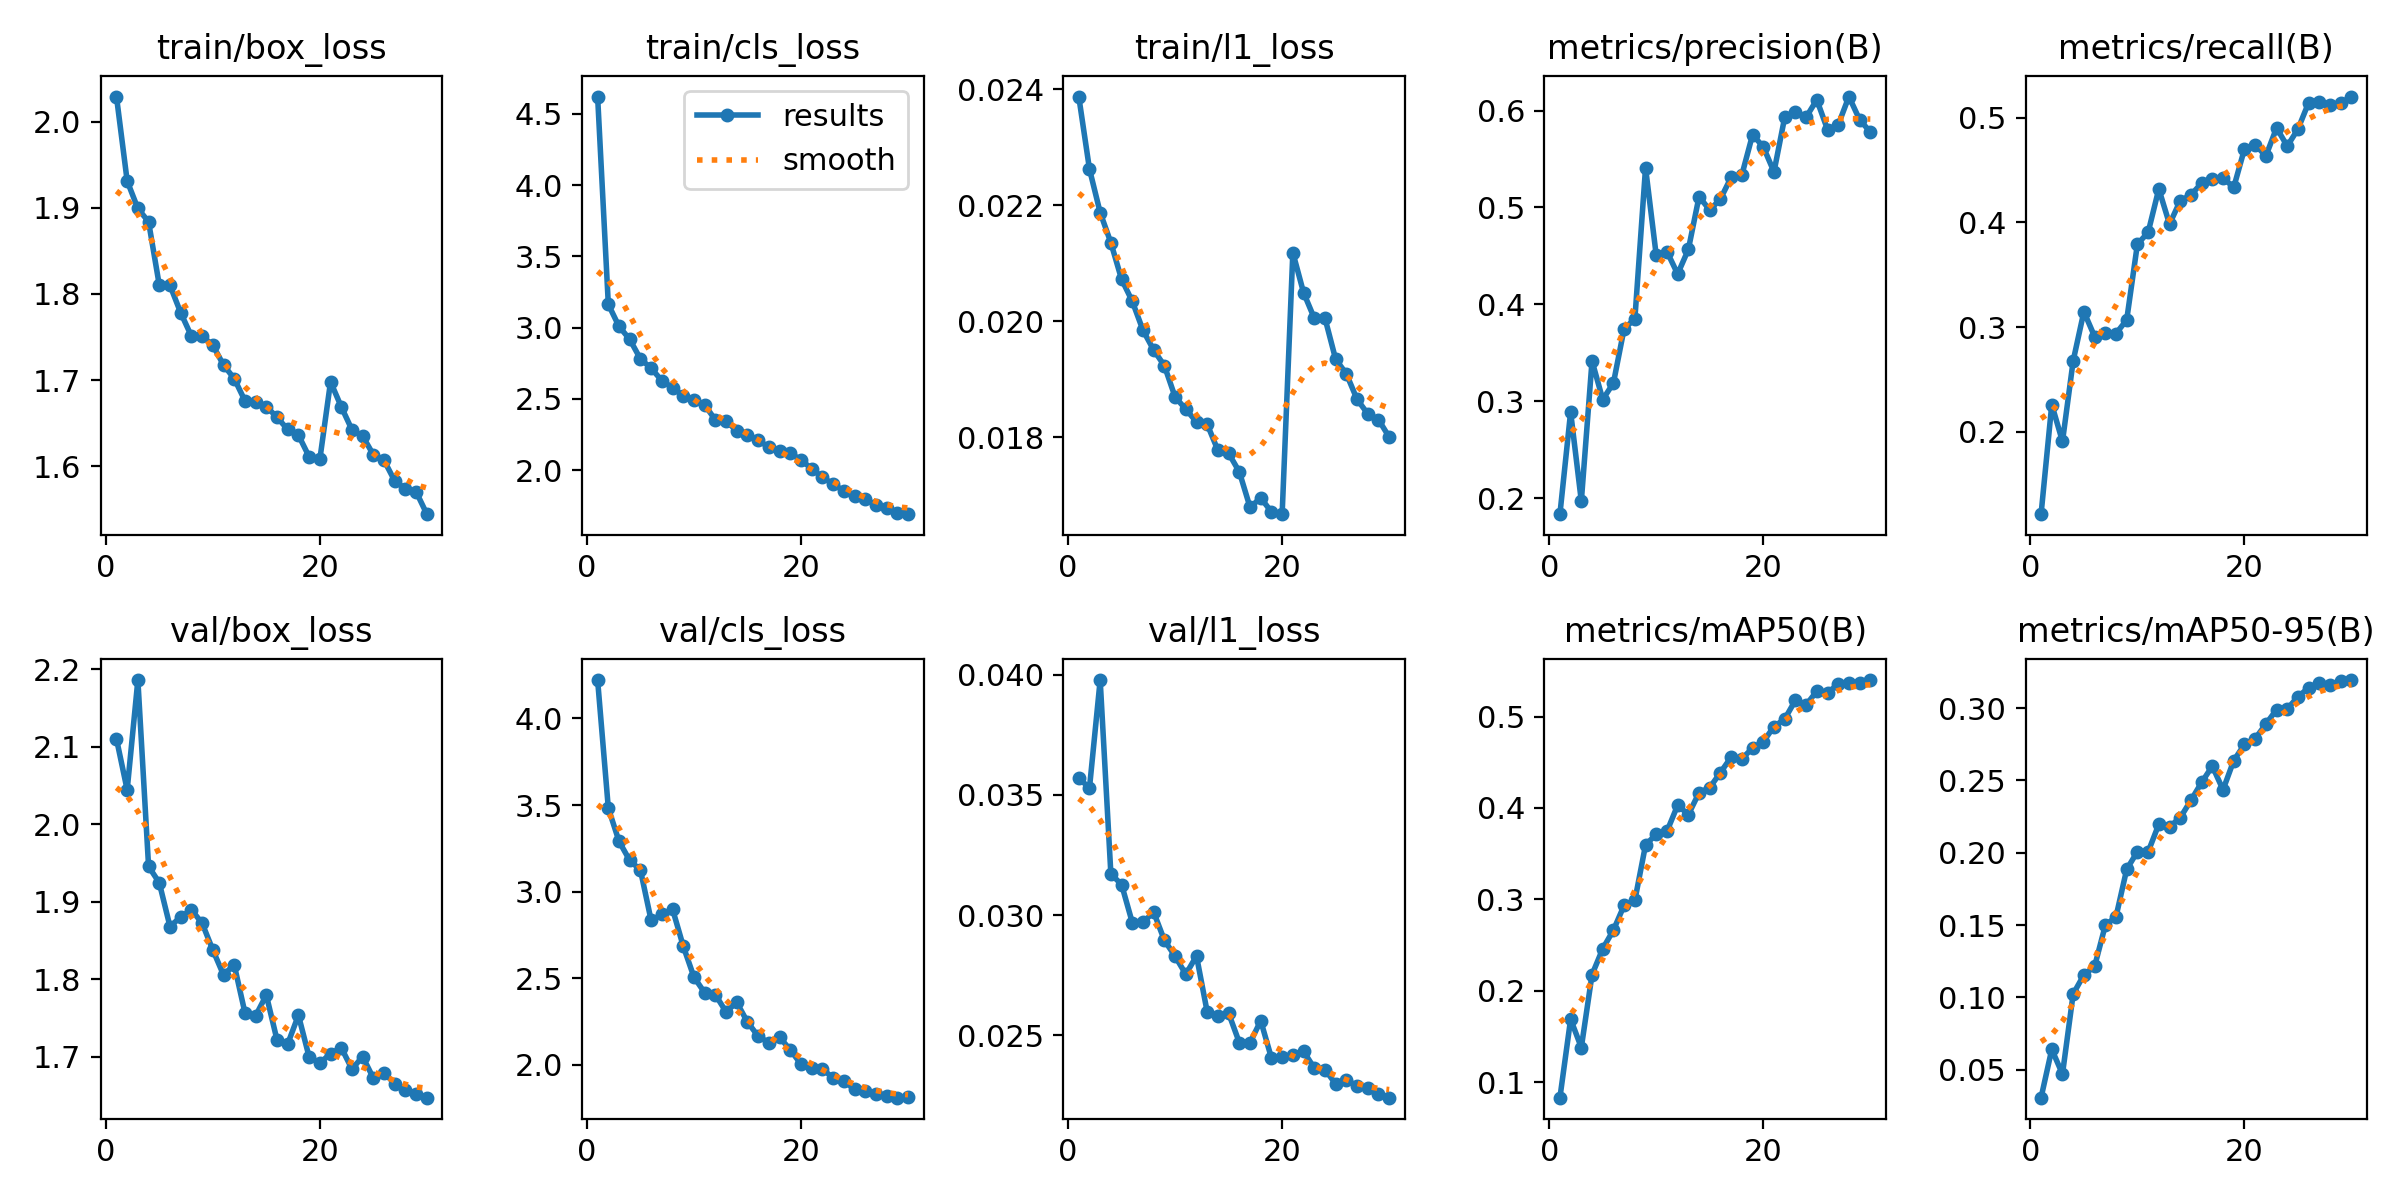

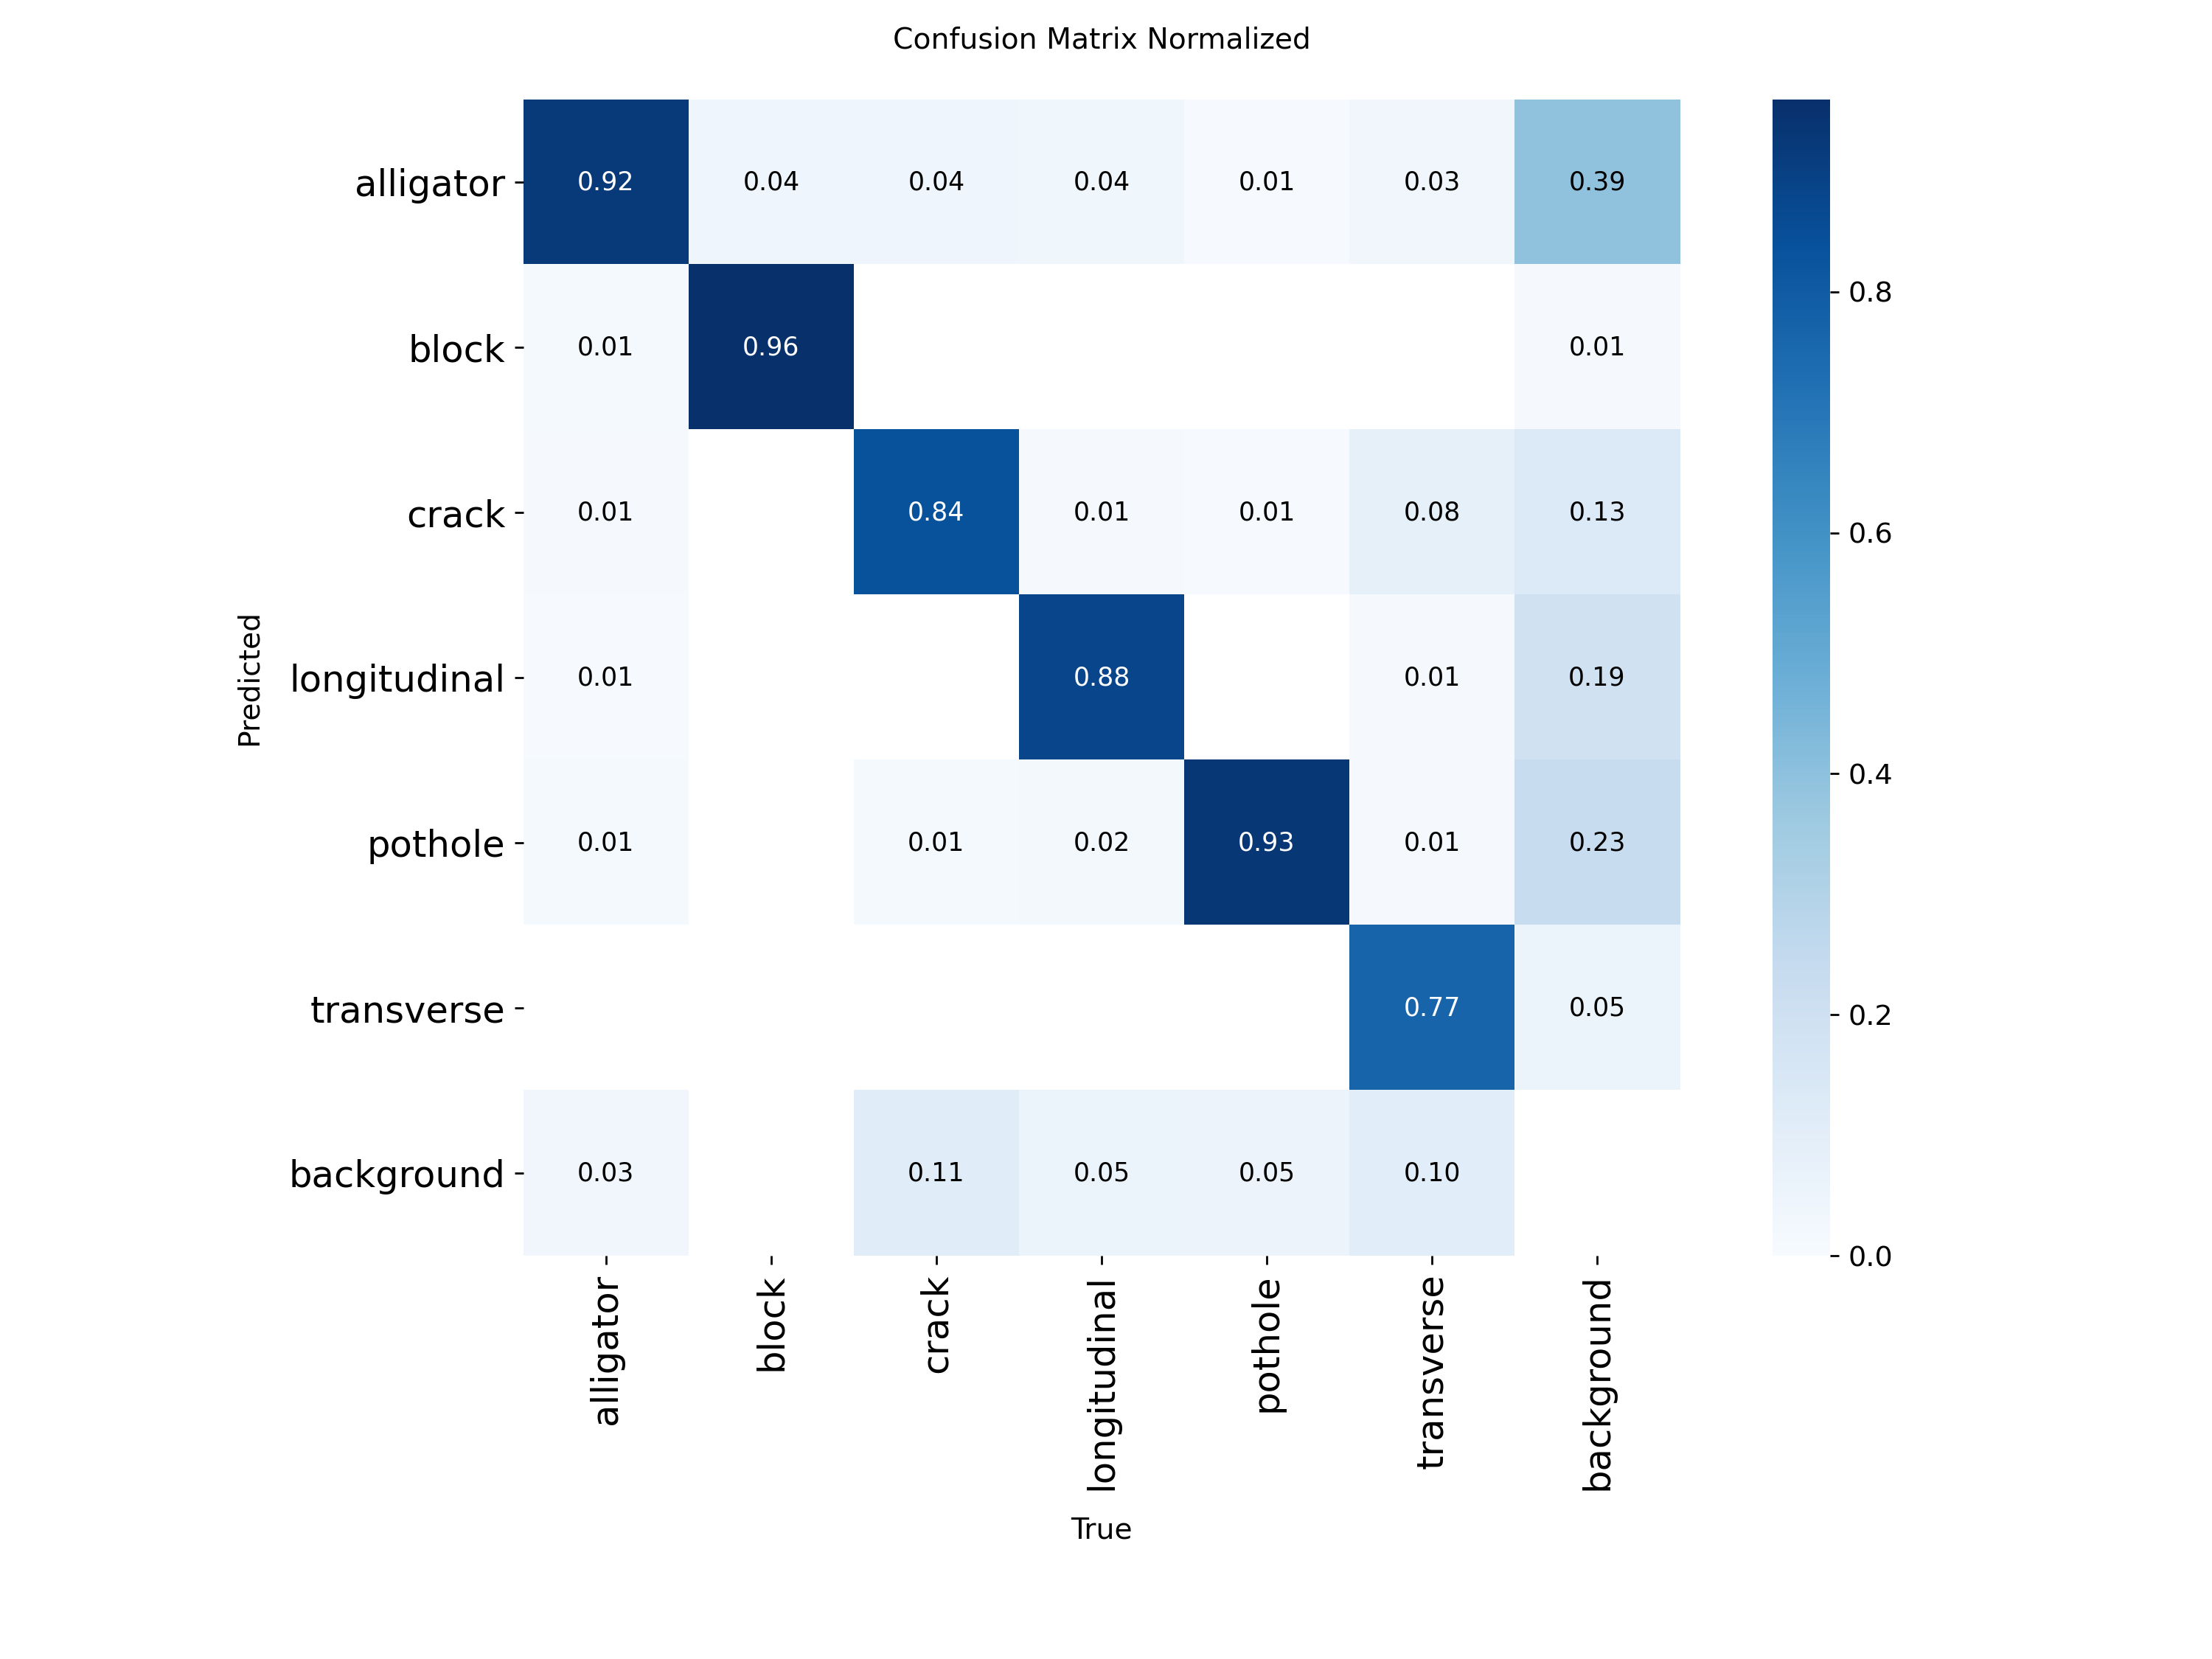

In [33]:
import pandas as pd
from IPython.display import Image, display

run_dir = Path(RUNS_DIR) / "yolo26s_imgsz800"
df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

display(df[["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(6))
display(Image(filename=str(run_dir / "results.png")))
display(Image(filename=str(run_dir / "confusion_matrix_normalized.png")))

In [34]:
shutil.make_archive("/kaggle/working/yolo26s_imgsz800_run", "zip", Path(RUNS_DIR) / "yolo26s_imgsz800")
print(os.listdir("/kaggle/working"))

['.virtual_documents', 'weights', 'yolo26s.pt', 'yolov8s.pt', 'yolo11s.pt', 'yolov11s_run.zip', 'road_damage_clean', 'yolo26s_imgsz800_run.zip', 'yolov8s_run.zip', 'road_damage_runs', 'yolov26s_run.zip']


### Results & Interpretation: Experiment E1 (imgsz = 800)
| Metric | Baseline (640) | E1 (800) |
|---|---|---|
| mAP50 | 0.548 | 0.539 |
| mAP50-95 | 0.328 | 0.320 |
| Precision / Recall | 0.612 / 0.512 | 0.581 / 0.516 |
| Train time (30 ep) | 41.8 min | 65.2 min |

**Decision: rejected.** No improvement (−0.008 mAP50-95, below the +0.01 acceptance threshold), 56% longer training, and mAP50-95 was lower for all six classes. The source images are natively 640×640, so upscaling adds no new detail; the small-object hypothesis is therefore not supported by this experiment, though it is not ruled out for higher-resolution data.

**Limits:** single run per setting (no variance estimate), 30 epochs only; a larger input size might need a different schedule to pay off.

## yolo26s-tune-ep50

In [35]:
assert torch.cuda.is_available(), "No GPU: enable an accelerator in Settings"
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


In [36]:
MODEL_NAME = "yolo26s"
EXP_NAME = "yolo26s_ep50"

t0 = time.time()
model = YOLO(MODELS[MODEL_NAME])
model.train(**{**BASE_CFG, "epochs": 50, "name": EXP_NAME})
print(f"{EXP_NAME} finished in {(time.time() - t0) / 60:.1f} min")

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_clean/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_ep50, nbs=64, nms=None, opset=None, o

,epoch,metrics/mAP50(B),metrics/mAP50-95(B)
44,45,0.54203,0.32824
45,46,0.54837,0.33073
46,47,0.55199,0.33089
47,48,0.54444,0.32865
48,49,0.54791,0.33179
49,50,0.54552,0.33099


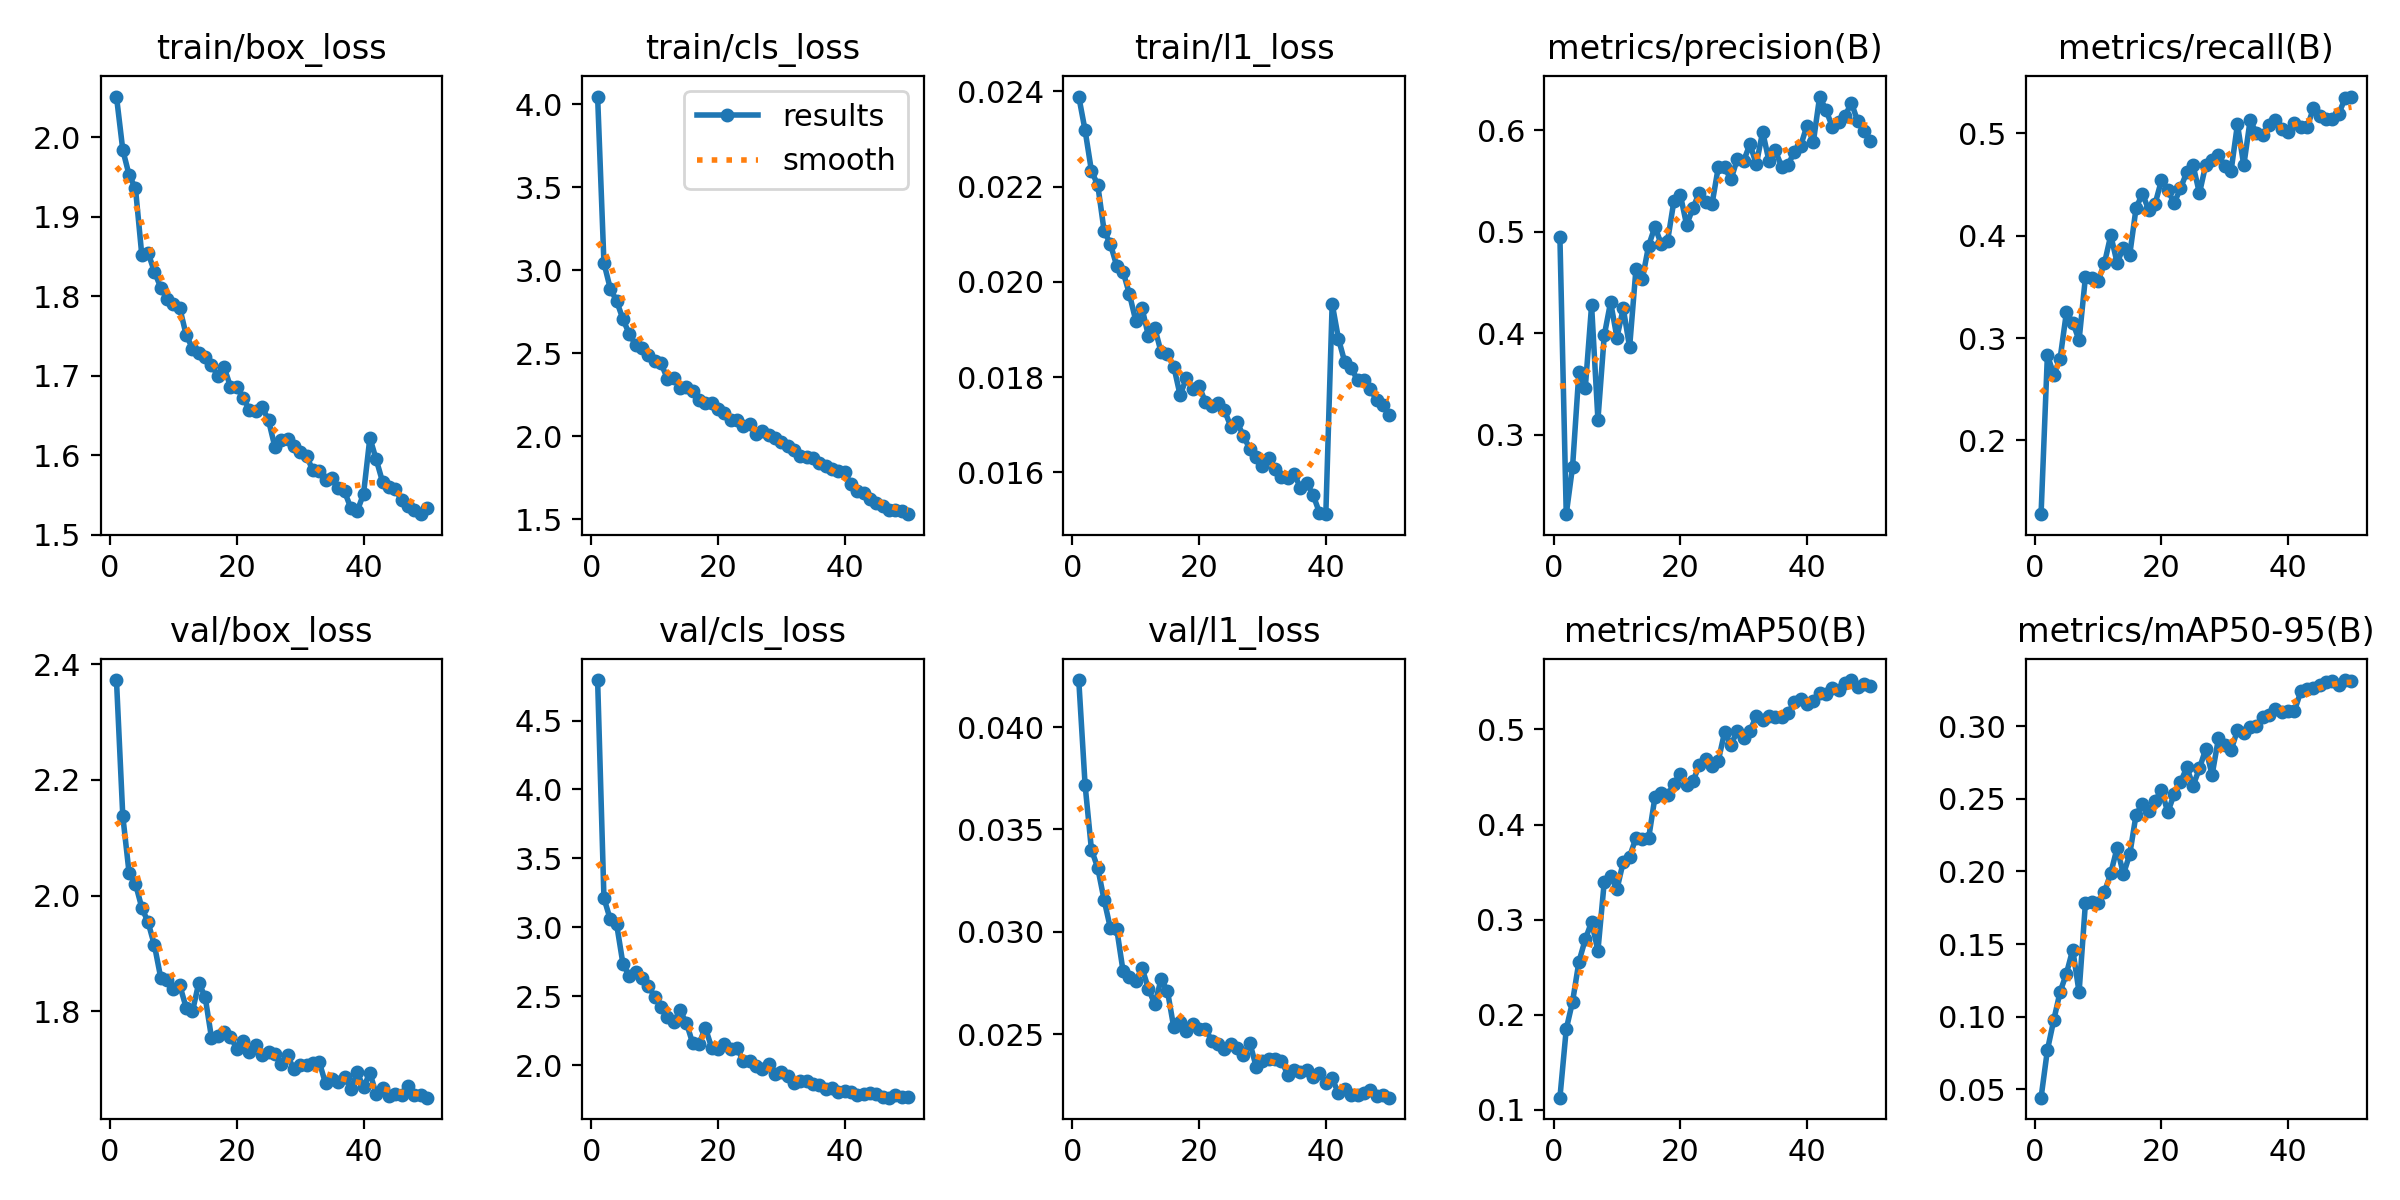

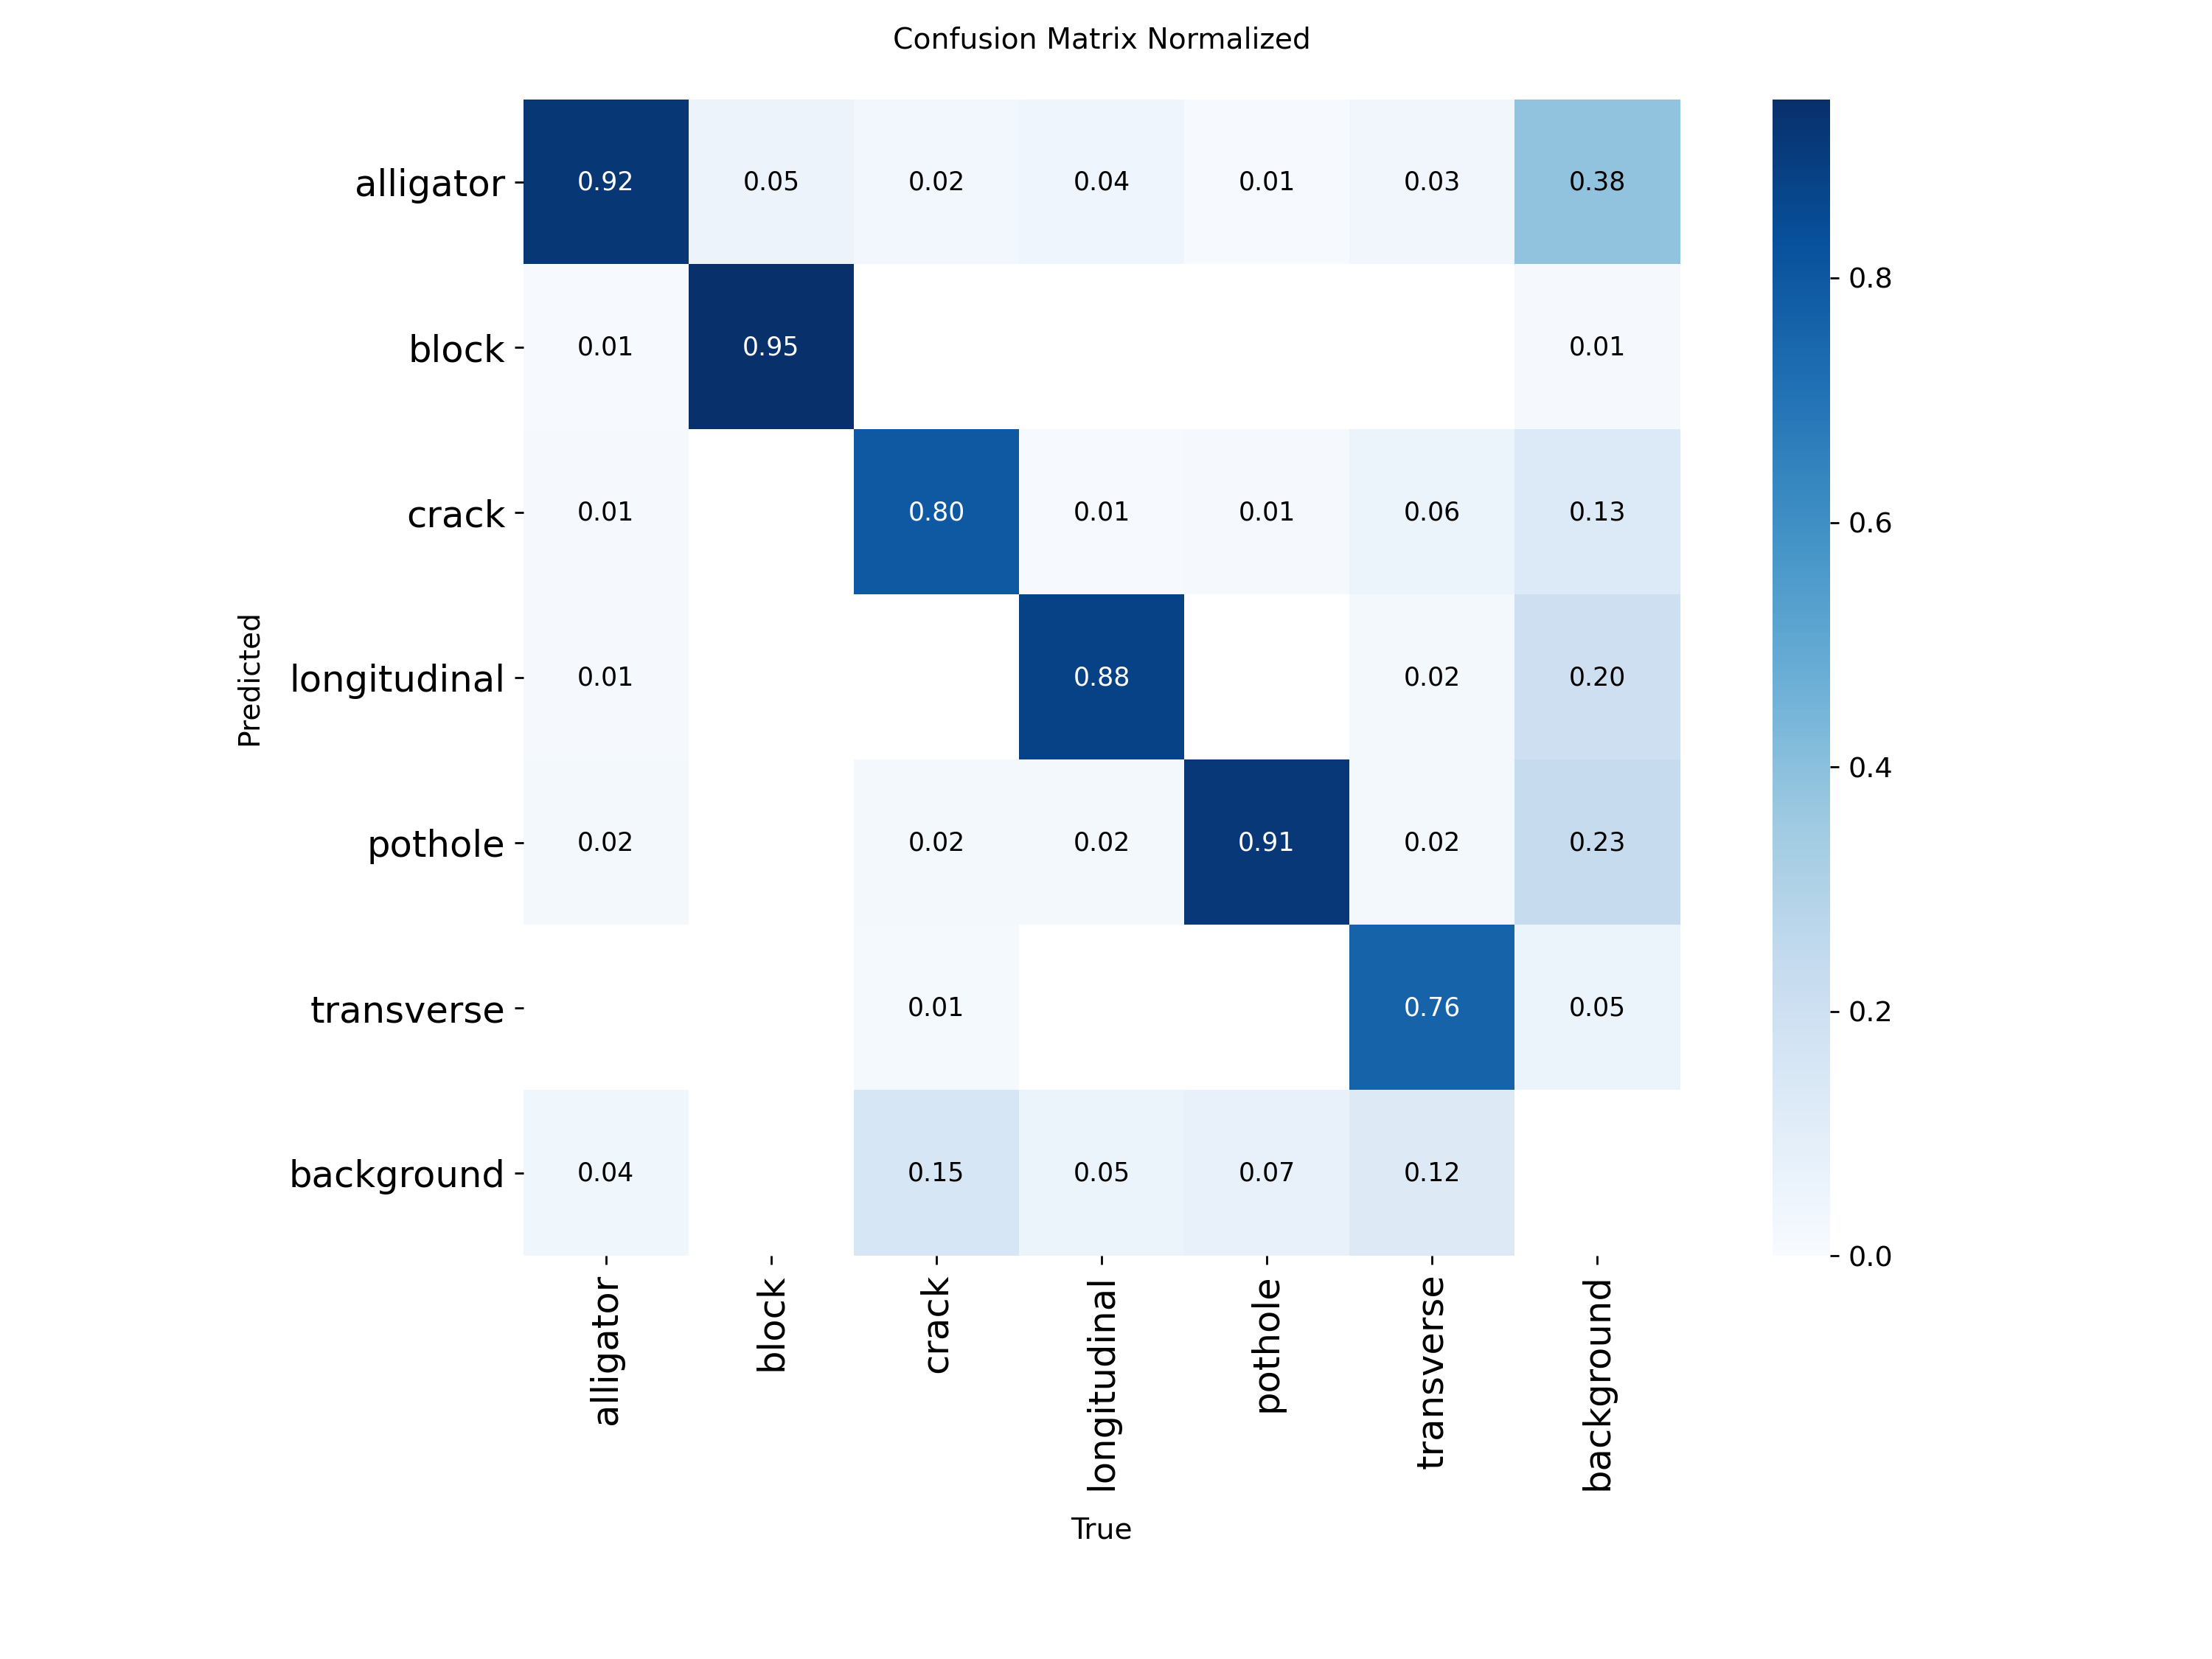

In [37]:
import pandas as pd
from IPython.display import Image, display

run_dir = Path(RUNS_DIR) / "yolo26s_ep50"
df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

display(df[["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(6))
display(Image(filename=str(run_dir / "results.png")))
display(Image(filename=str(run_dir / "confusion_matrix_normalized.png")))

In [38]:
shutil.make_archive("/kaggle/working/yolo26s_ep50_run", "zip", Path(RUNS_DIR) / "yolo26s_ep50")
print(os.listdir("/kaggle/working"))

['.virtual_documents', 'weights', 'yolo26s.pt', 'yolov8s.pt', 'yolo11s.pt', 'yolo26s_ep50_run.zip', 'yolov11s_run.zip', 'road_damage_clean', 'yolo26s_imgsz800_run.zip', 'yolov8s_run.zip', 'road_damage_runs', 'yolov26s_run.zip']


### Results & Interpretation: Experiment E2 (epochs = 50)
| Metric | Baseline (30 ep) | E2 (50 ep) |
|---|---|---|
| mAP50 | 0.548 | 0.548 |
| mAP50-95 | 0.328 | 0.332 |
| Precision / Recall | 0.612 / 0.512 | 0.588 / 0.543 |
| Train time | 41.8 min | 69.9 min |

**Decision: rejected.** The gain (+0.004 mAP50-95) is below the +0.01 acceptance threshold set before the run, while training took 67% longer. mAP50-95 plateaued around 0.33 over the last epochs and the run did not early-stop, so under-training is not supported.

**Tuning summary:** two one-factor experiments on the best baseline (YOLO26s), `imgsz=800` and `epochs=50`, both rejected; the baseline configuration is retained.

**Limits:** single run per setting (no variance estimate); precision/recall are reported at each model's own best-F1 threshold, so they are not directly comparable, unlike mAP; `lr0` and augmentation settings were not explored, and only the best model was tuned.